<a href="https://colab.research.google.com/github/debashisdotchatterjee/Annealed_Gromov_1/blob/main/Annealed_Gromov_Original_Plus_TLC_Daily.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Annealed Gromov signatures — original simulation + appended real-data application

**The original simulation source is preserved without modification.** This notebook
adds a daily NYC TLC taxi-zone geometric application *after* the previously supplied
simulation. Set `RUN_PREVIOUS_SIMULATION=False` to avoid repeating experiments already
completed. The real-data study writes its own independent output directory and ZIP.

**Empirical units:** calendar-day metric–measure spaces supported on official taxi
zones; metric = fixed Haversine distance between zone polygon centroids; measure =
daily normalized pickup-zone frequencies. Numerical features are finite invariant
Gaussian signatures, orders 2–4. Unlike the synthetic four-point case, tuples are
Monte Carlo sampled from each empirical measure **with replacement**. This is a
V-statistic approximation, with independently evaluated numerical disagreement.

**Inferential scope:** p-values are *exploratory Gaussian reference sensitivities*;
serial dependence, seasonality and nonstationarity invalidate automatic theorem-level
size claims. There are no invented empirical observations or significance claims.

**Source:** [Official TLC record archive](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page);
[Official NYC Taxi Zone polygons](https://data.cityofnewyork.us/Transportation/NYC-Taxi-Zones/8meu-9t5y).


## 1. Dependencies and configuration

In [ ]:
%pip -q install numpy scipy pandas matplotlib scikit-learn shapely pyarrow tabulate nbformat

In [1]:
# Edit only this cell. The simulation code beneath remains unchanged.
RUN_PREVIOUS_SIMULATION = False  # Already completed: leave False
RUN_TLC_REAL_DATA = True
USE_SYNTHETIC_TEST_FIXTURE = False  # For software diagnostics only, never a real-data finding
START_MONTH = '2019-07'
END_MONTH = '2020-12'
FIXED_EVENT_DATE = '2020-03-16'
CLOUD_TUPLES = 5000       # Per order and independent batch; two batches are averaged
GAUSSIAN_DRAWS = 299      # Monte Carlo reference sensitivity; 399 or 999 if desired
ZONE_LANDMARKS = 12
MIN_DAILY_PICKUPS = 350
BLOCK_LENGTHS = '7,14,28'
REUSE_CACHE_DIR = '/content/tlc_taxi_cache'
REAL_DATA_OUTPUT = '/content/annealed_tlc_daily_outputs'
PREVIOUS_SIM_OUTPUT = '/content/annealed_fast_results'
SEED = 2088


## 2. Unchanged previous simulation source
The next cell writes the same simulation program previously delivered.

In [2]:
from pathlib import Path
Path("annealed_fast_simulation.py").write_text('#!/usr/bin/env python3\n"""Fast, reproducible, finite-cloud simulations for Annealed Gromov Signatures.\n\nSynthetic spaces here have FOUR support points.  Therefore the *complete*,\nconditionally unbiased ordered U-statistic over the observed i.i.d. cloud can\nbe evaluated exactly from four occupancy counts.  No observed-cloud randomness\nis bypassed; only superfluous random tuple integration is removed. This exact\nfinite-support optimization must not be confused with an algorithm applicable\nto arbitrary continuous geometries.\n\nHigher-order invariant distances use a canonical distance-array representative\n(minimum over vertex relabellings), preserving full isometry-class information\nat orders 2, 3, and 4. A finite feature dictionary is NOT an omnibus kernel.\n\nOnly simulation results, never empirical observations, are generated.\n\nRequirements: numpy, scipy, pandas, matplotlib; Python >= 3.10.\nExample: python annealed_fast_simulation.py --profile research --out results_gromov\nResume:  python annealed_fast_simulation.py --profile research --out results_gromov --resume\n"""\nfrom __future__ import annotations\nimport argparse, hashlib, itertools, json, math, os, platform, shutil, sys, time, traceback, zipfile\nfrom dataclasses import asdict, dataclass\nfrom datetime import datetime, timezone\nfrom fractions import Fraction\nfrom pathlib import Path\nfrom scipy.special import ndtr\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\n\nSEED = 2088\nCOL = {\'ink\':\'#213247\',\'blue\':\'#2C5689\',\'orange\':\'#D38B49\',\n       \'teal\':\'#148A85\',\'red\':\'#B14B5B\',\'grey\':\'#768395\',\'violet\':\'#7761A4\'}\nplt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'font.size\':10,\'axes.titlesize\':11,\n  \'figure.dpi\':130,\'savefig.dpi\':250,\'axes.spines.top\':False,\'axes.spines.right\':False,\n  \'axes.grid\':True,\'grid.alpha\':0.16,\'legend.frameon\':False})\n\n@dataclass(frozen=True)\nclass Experiment:\n    key: str\n    scenario: str\n    T: int\n    q: int\n    cloud: str = \'moderate\'\n\nEXPERIMENTS = (\n    Experiment(\'null_iid_120\',\'null\',120,0),\n    Experiment(\'null_q1_180\',\'null\',180,1),\n    Experiment(\'null_q3_180\',\'null\',180,3),\n    Experiment(\'blindspot_120\',\'blindspot\',120,1),\n    Experiment(\'blindspot_240\',\'blindspot\',240,1),\n    Experiment(\'measure_180\',\'measure\',180,1),\n    Experiment(\'scale_180\',\'scale\',180,1),\n    Experiment(\'local_240\',\'local\',240,1),\n    Experiment(\'null_slow_180\',\'null\',180,1,\'slow\'),\n)\nMETHODS = (\'baseline2\',\'baseline3\',\'enhanced2\',\'enhanced3\',\'enhanced4\',\'patterns3\')\nBLOCK_ORDERS = {\'baseline2\':(2,), \'baseline3\':(2,3), \'enhanced2\':(2,),\n                \'enhanced3\':(2,3), \'enhanced4\':(2,3,4), \'patterns3\':(2,3)}\n\ndef savefig(fig, path):\n    path.parent.mkdir(parents=True,exist_ok=True)\n    for ext in (\'.png\',\'.pdf\'):\n        fig.savefig(path.with_suffix(ext),bbox_inches=\'tight\',facecolor=\'white\')\n    plt.close(fig)\n\ndef persist_table(df, root, name, caption, label):\n    root.mkdir(parents=True,exist_ok=True)\n    df.to_csv(root/(name+\'.csv\'),index=False,float_format=\'%.10g\')\n    (root/(name+\'.tex\')).write_text(df.to_latex(index=False,escape=True,\n                        caption=caption,label=label,float_format=lambda x:f\'{x:.4g}\'),encoding=\'utf8\')\n\ndef canonical(D,k,vertices,perms):\n    S=D[np.ix_(vertices,vertices)]\n    return min(tuple(round(float(S[p[i],p[j]]),5)\n         for i in range(k) for j in range(i+1,k)) for p in perms)\n\ndef all_distances():\n    edges=list(itertools.combinations(range(4),2))\n    return [("graph%02d_%s"%(bits,str(scale)),make_matrix(bits,scale))\n            for bits in range(64) for scale in (1.,1.3)]\n\ndef make_matrix(bits,scale=1.):\n    edges=list(itertools.combinations(range(4),2))\n    D=np.full((4,4),2.*scale);np.fill_diagonal(D,0.)\n    for a,(i,j) in enumerate(edges):\n        if bits & (1<<a):D[i,j]=D[j,i]=scale\n    return D\n\ndef space(name):\n    graphs={\'star\':((0,1),(0,2),(0,3)),\n        \'path\':((0,1),(1,2),(2,3)),\n        \'complete\':tuple(itertools.combinations(range(4),2)),\n        \'cycle\':((0,1),(1,2),(2,3),(0,3))}\n    kind=name.replace(\'_mass\',\'\').replace(\'_scale\',\'\')\n    D=np.full((4,4),2.);np.fill_diagonal(D,0.)\n    for a,b in graphs[kind]:D[a,b]=D[b,a]=1.\n    p=np.ones(4)/4\n    if name==\'star_mass\':p=np.array([.46,.18,.18,.18])\n    if name==\'star_scale\':D*=1.3\n    return D,p\n\ndef all_pattern_catalogs():\n    """Prespecified model-class vocabulary: all simple four-vertex graphs at two scales.\n\n    Only the geometry family and unit conventions, NOT generated realizations or\n    alternative labels, enter the dictionary; comparison is truly paired.\n    """\n    mats=all_distances(); catalogs={};tuples={};permutations={}\n    for k in (2,3,4):\n        vv=list(itertools.product(range(4),repeat=k));pp=list(itertools.permutations(range(k)))\n        value=set()\n        for _,D in mats:\n            for v in vv:value.add(canonical(D,k,v,pp))\n        catalogs[k]=sorted(value)\n        tuples[k]=np.asarray(vv,dtype=np.int8)\n        permutations[k]=pp\n    return catalogs,tuples,permutations\n\ndef falling(n,k):\n    r=np.ones_like(np.asarray(n,dtype=np.float64))\n    for j in range(k):r*=np.maximum(0,np.asarray(n,dtype=np.float64)-j)\n    return r\n\ndef multiplicities(k):\n    return np.asarray([p for p in itertools.product(range(k+1),repeat=4) if sum(p)==k],dtype=np.int8)\n\ndef original_centres(k, R=6):\n    levels=[0.,1.,2.,.5,1.5]\n    triples=[[1.,1.,2.],[1.,2.,1.],[2.,1.,1.],[1.,1.,1.],[2.,2.,2.],[0.,0.,0.]]\n    rng=np.random.default_rng(1871)\n    if k==2:\n        vv=[[x] for x in levels]\n        while len(vv)<R:vv.append(rng.choice(levels,size=1).tolist())\n        return np.array(vv[:R],float)\n    if k==3:return np.array(triples[:R],float)\n    raise ValueError(k)\n\ndef calc_gauss(data,centers,bandwidth):\n    data=np.asarray(data,float);centers=np.asarray(centers,float)\n    dist2=((data[:,None,:]-centers[None,:,:])**2).sum(axis=2)\n    return np.exp(-dist2/(bandwidth**2))\n\nclass FiniteFourPointEngine:\n    def __init__(self,bandwidth=0.75):\n        self.catalog,self.tuples,self.perms=all_pattern_catalogs()\n        self.multip={k:multiplicities(k) for k in (2,3,4)}\n        self.tables={}\n        self.bandwidth=bandwidth\n        self.kern={k:calc_gauss(self.catalog[k],self.catalog[k],\n                       bandwidth*np.sqrt(k*(k-1)/2)) for k in (2,3,4)}\n        self.kern={k:self.kern[k]/np.sqrt(len(self.catalog[k])) for k in (2,3,4)}\n        self.spaces={name:space(name) for name in\n            (\'complete\',\'star\',\'path\',\'cycle\',\'star_mass\',\'star_scale\')}\n        for name,(D,p) in self.spaces.items():\n            self.tables[name]={}\n            for k in (2,3,4):\n                vv=self.tuples[k];mu=self.multip[k]\n                ix={tuple(v):j for j,v in enumerate(mu.tolist())}\n                idx={v:j for j,v in enumerate(self.catalog[k])}\n                C=np.zeros((len(mu),len(self.catalog[k])),float)\n                A=np.zeros((len(mu),6),float) if k in (2,3) else None\n                bases=original_centres(k) if k in (2,3) else None\n                pair_idx=np.triu_indices(k,1)\n                for seq in vv:\n                    mid=ix[tuple(np.bincount(seq,minlength=4))]\n                    C[mid,idx[canonical(D,k,seq,self.perms[k])]]+=1.\n                    if A is not None:\n                        raw=D[np.ix_(seq,seq)][pair_idx]\n                        A[mid,:]+=np.exp(-np.sum((bases-raw)**2,axis=1))\n                self.tables[name][k]=(C,A)\n        self._check()\n\n    def _check(self):\n        assert [len(self.catalog[k]) for k in (2,3,4)]==[5,13,43]\n        for name in self.spaces:\n            for k in (2,3,4):\n                C,_=self.tables[name][k]\n                expected=np.array([math.factorial(k)/np.prod([math.factorial(int(v)) for v in r])\n                         for r in self.multip[k]])\n                # For fixed occupancy multiplicities there are k!/prod(r!) sequences.\n                assert np.allclose(C.sum(axis=1),expected)\n\n    def weights_from_clouds(self,counts,k):\n        counts=np.asarray(counts,float);m=counts.sum(axis=1)\n        assert np.all(m>=k)\n        mu=self.multip[k]\n        W=np.ones((len(counts),len(mu)))\n        for i in range(4):\n            r=mu[:,i]\n            # (n)_r over each sample & category, distinct observation indices.\n            ff=np.ones((len(counts),k+1))\n            for j in range(1,k+1):ff[:,j]=ff[:,j-1]*np.maximum(counts[:,i]-(j-1),0)\n            W*=ff[:,r]\n        W/=falling(m,k)[:,None]\n        return W\n\n    def compute(self,cats,counts):\n        """Return all method matrices, using exact complete U-statistics per cloud."""\n        cats=np.asarray(cats);counts=np.asarray(counts);T=len(cats)\n        H={k:np.zeros((T,len(self.catalog[k]))) for k in (2,3,4)}\n        B={k:np.zeros((T,6)) for k in (2,3)}\n        for k in (2,3,4):\n            weights=self.weights_from_clouds(counts,k)\n            for name in np.unique(cats):\n                mask=(cats==name)\n                C,A=self.tables[name][k]\n                H[k][mask]=weights[mask]@C\n                if A is not None:B[k][mask]=weights[mask]@A\n            assert np.max(np.abs(H[k].sum(axis=1)-1))<1e-10\n        # Original coordinate weights, reproduced for direct baseline comparison.\n        orig={k:B[k]*np.sqrt(2.**(-(k-1))*2.**(-np.arange(1,7))) for k in (2,3)}\n        # Enhanced Gaussian features: permutation-invariant centres, fixed scaling.\n        g={k:H[k]@self.kern[k] for k in (2,3,4)}\n        # Equal order weights facilitate detection; every coordinate is bounded.\n        g={k:v/np.sqrt(3) for k,v in g.items()}\n        # Diagnostic discrete-pattern method is a separate finite-basis comparator.\n        p={k:H[k]/np.sqrt(3) for k in (2,3,4)}\n        return {\'baseline2\':orig[2], \'baseline3\':np.column_stack((orig[2],orig[3])),\n             \'enhanced2\':g[2], \'enhanced3\':np.column_stack((g[2],g[3])),\n             \'enhanced4\':np.column_stack((g[2],g[3],g[4])),\n             \'patterns3\':np.column_stack((p[2],p[3]))},H\n\n    def population(self,name):\n        """Unconditional feature expectation given a *fixed* 4-point geometry."""\n        p=self.spaces[name][1]\n        H={};B={}\n        for k in (2,3,4):\n            mu=self.multip[k]\n            w=np.prod(p[None,:]**mu,axis=1)  # ordered independent sampled vertices\n            C,A=self.tables[name][k]\n            H[k]=w@C\n            if A is not None:B[k]=w@A\n            assert abs(H[k].sum()-1)<1e-10\n        orig={k:B[k]*np.sqrt(2.**(-(k-1))*2.**(-np.arange(1,7))) for k in (2,3)}\n        g={k:H[k]@self.kern[k]/np.sqrt(3) for k in (2,3,4)}\n        motif={k:H[k]/np.sqrt(3) for k in (2,3)}\n        return {\'baseline2\':orig[2],\'baseline3\':np.r_[orig[2],orig[3]],\n            \'enhanced2\':g[2],\'enhanced3\':np.r_[g[2],g[3]],\n            \'enhanced4\':np.r_[g[2],g[3],g[4]],\n            \'patterns3\':np.r_[motif[2],motif[3]]},H\n\n\ndef simulate_cats(T,q,scenario,rng,local_strength=2.,noise=.35):\n    innov=rng.standard_normal(T+q)\n    z=sum(innov[i:i+T] for i in range(q+1))/np.sqrt(q+1)\n    u=ndtr(z);post=(np.arange(T)>=T//2)\n    cats=np.full(T,\'star\',dtype=\'U12\');cats[u<noise]=\'complete\'\n    if scenario==\'blindspot\':cats[(u>=noise)&post]=\'path\'\n    elif scenario==\'measure\':cats[(u>=noise)&post]=\'star_mass\'\n    elif scenario==\'scale\':cats[(u>=noise)&post]=\'star_scale\'\n    elif scenario==\'local\':\n        p_path=min(.95,local_strength/np.sqrt(T))\n        cats[(u>=noise)&(u<noise+(1-noise)*p_path)&post]=\'path\'\n    elif scenario!=\'null\':raise ValueError(\'Unknown scenario \'+scenario)\n    return cats\n\ndef clouds_for_cats(cats,T,cloud,rng):\n    if cloud==\'slow\': m_min=max(4,int(np.ceil(np.log(np.log(T+np.exp(np.e))))))\n    elif cloud==\'moderate\':m_min=max(14,3*int(np.ceil(T**0.25)))\n    elif cloud==\'large\':m_min=max(32,int(np.ceil(np.sqrt(T)*2)))\n    else:raise ValueError(cloud)\n    m=m_min+2*(np.arange(T)%3)\n    counts=np.zeros((T,4),dtype=np.int16)\n    for name in np.unique(cats):\n        ids=np.where(cats==name)[0];p=space(name)[1]\n        for j in ids:counts[j]=rng.multinomial(int(m[j]),p)\n    return counts,m_min\n\ndef cusum(Y,eta=0.1):\n    Y=np.asarray(Y,dtype=float);T=len(Y)\n    cum=np.concatenate((np.zeros((1,Y.shape[1])),np.cumsum(Y,axis=0)),axis=0)\n    u=np.arange(T+1)/T\n    bridge=(cum-u[:,None]*cum[-1])/np.sqrt(T)\n    length=np.linalg.norm(bridge,axis=1)\n    a=int(np.ceil(T*eta));b=int(np.floor(T*(1-eta)))\n    j=a+int(np.argmax(length[a:b+1]))\n    return float(length[j]),j,bridge,length\n\ndef calibrated(Y,rng,B=199,alpha=.05,eta=.1,q=1):\n    """PSD nonoverlapping-block covariance + EXACT-GRID Gaussian bridge draws.\n\n    Reference law asymptotic under stationary q-dependence. The same Monte\n    Carlo formula is applied under fixed alternatives as a test construction.\n    No dimension reduction of Y is needed: use nonzero eigenvalues of blocks.\n    """\n    Y=np.asarray(Y,dtype=float);T,d=Y.shape\n    observed,cp,_,_=cusum(Y,eta)\n    # Memory-aware, predeclared finite-T block length (asymptotically b~T^(1/3)).\n    b=max(2*(q+1),math.ceil(T**(1/3))+2)\n    blocks=T//b\n    if blocks<3:raise ValueError(\'Too few blocks\')\n    Z=Y-Y.mean(axis=0)\n    V=Z[:blocks*b].reshape(blocks,b,d).sum(axis=1)/np.sqrt(b)\n    # nonzero eigenvalues of V.T@V / B equal those of V@V.T / B:\n    eig=np.linalg.eigvalsh((V@V.T)/blocks)\n    eig=np.maximum(eig,0.)\n    eig=eig[eig>max(1e-14,float(eig.max(initial=0))*1e-12)]\n    if len(eig)==0:\n        return dict(stat=observed,cp_index=cp,pvalue=np.nan,critical=np.nan,\n             reject=np.nan,block=b,rank=0,trace=0.,degenerate=True)\n    a=int(np.ceil(T*eta));f=int(np.floor(T*(1-eta)))\n    u=np.arange(1,T+1,dtype=float)/T\n    maxima=[]\n    batch=64\n    for i in range(0,B,batch):\n        nb=min(batch,B-i)\n        inc=rng.standard_normal((nb,T,len(eig)))/np.sqrt(T)\n        bw=np.cumsum(inc,axis=1)\n        bw-=u[None,:,None]*bw[:,-1:,:]\n        sq=np.einsum(\'btr,r->bt\',bw*bw,eig,optimize=True)\n        maxima.append(np.sqrt(np.max(sq[:,a-1:f],axis=1)))\n    draws=np.concatenate(maxima)\n    p=(1+np.count_nonzero(draws>=observed))/(B+1)\n    return dict(stat=observed,cp_index=cp,pvalue=p,\n       critical=float(np.quantile(draws,1-alpha)),reject=bool(p<=alpha),\n       block=b,rank=len(eig),trace=float(eig.sum()),degenerate=False)\n\ndef wilson(k,n):\n    if n==0:return (np.nan,np.nan)\n    z=1.959963984540054;v=k/n;den=1+z*z/n\n    center=(v+z*z/(2*n))/den\n    width=z*np.sqrt((v*(1-v)+z*z/(4*n))/n)/den\n    return (0.0 if k==0 else max(0.0,center-width)),(1.0 if k==n else min(1.0,center+width))\n\ndef exact_reference(engine,where):\n    # Verify invariance, pair-blindness and specific ordered wedge probabilities.\n    ex=where/\'01_exact\';ex.mkdir(parents=True,exist_ok=True)\n    star,Dstar=engine.spaces[\'star\'];path,Dpath=engine.spaces[\'path\']\n    a=engine.population(\'star\')[1];b=engine.population(\'path\')[1]\n    assert np.allclose(a[2],b[2],atol=1e-15)\n    wedge=(1.,1.,2.);wedge_count={}\n    for name,(D,p) in [(\'star\',engine.spaces[\'star\']),(\'path\',engine.spaces[\'path\'])]:\n        total=Fraction(0)\n        for tup in itertools.product(range(4),repeat=3):\n            x=tuple(int(D[tup[i],tup[j]]) for i,j in ((0,1),(0,2),(1,2)))\n            if x==(1,1,2):total+=Fraction(1,64)\n        wedge_count[name]=total\n    assert wedge_count[\'star\']==Fraction(3,32)\n    assert wedge_count[\'path\']==Fraction(1,16)\n    rows=[]\n    for method in METHODS:\n        v1=engine.population(\'star\')[0][method]\n        v2=engine.population(\'path\')[0][method]\n        rows.append({\'method\':method,\'dimension\':len(v1),\n          \'star_path_population_norm\':float(np.linalg.norm(v1-v2)),\n          \'mixture_mean_shift_0p65\':float(.65*np.linalg.norm(v1-v2))})\n    table=pd.DataFrame(rows)\n    assert table.loc[table.method==\'enhanced2\',\'star_path_population_norm\'].iloc[0]<1e-13\n    assert table.loc[table.method==\'patterns3\',\'star_path_population_norm\'].iloc[0]>0.01\n    persist_table(table,ex,\'population_shifts\',\'Exact population embedding distances for the prespecified finite dictionaries\',\'tab:fast-shifts\')\n    (ex/\'exact_checks.json\').write_text(json.dumps({\'ordered_wedge_star\':str(wedge_count[\'star\']),\n         \'ordered_wedge_path\':str(wedge_count[\'path\']),\n         \'equal_pair_laws\':True,\'cloud_full_Ustatistic\':True,\n         \'finite_dictionary_not_characteristic_on_all_metric_spaces\':True,\n         \'catalog_sizes\':{str(k):len(v) for k,v in engine.catalog.items()}},indent=2))\n    fig,axes=plt.subplots(1,2,figsize=(11.5,4.0))\n    labs=list(table.method); xx=np.arange(len(labs))\n    axes[0].bar(xx,table.mixture_mean_shift_0p65,color=[COL[\'grey\'] if \'2\' in x else COL[\'teal\'] for x in labs])\n    axes[0].set_xticks(xx,labs,rotation=40,ha=\'right\')\n    axes[0].set_ylabel(\'Norm of population mean shift\')\n    axes[0].set_title(\'(a) Prespecified finite feature families\')\n    w_a=a[3];w_b=b[3];ix=np.argsort(-np.abs(w_a-w_b))[:8]\n    axes[1].bar(np.arange(len(ix))-.19,w_a[ix],.38,color=COL[\'blue\'],label=\'Star\')\n    axes[1].bar(np.arange(len(ix))+.19,w_b[ix],.38,color=COL[\'orange\'],label=\'Path\')\n    axes[1].set_xticks(range(len(ix)),[str(engine.catalog[3][i]) for i in ix],rotation=60,ha=\'right\',fontsize=7)\n    axes[1].set_ylabel(\'Exact unordered-pattern probability\')\n    axes[1].set_title(\'(b) Order-three canonical distance patterns\')\n    axes[1].legend()\n    fig.suptitle(\'Identical two-point laws need not imply identical three-point laws\',y=1.015)\n    fig.tight_layout();savefig(fig,ex/\'fig01_exact_signal_and_motifs\')\n    return table\n\ndef atomic_csv(rows,path):\n    tmp=path.with_suffix(\'.tmp\')\n    pd.DataFrame(rows).to_csv(tmp,index=False)\n    os.replace(tmp,path)\n\ndef setup_results(out,experiments,seed,profile,reps,B,bandwidth,methods):\n    meta={\'study\':\'Fast exact-complete-U finite support Gromov study\',\n       \'created_at_utc\':datetime.now(timezone.utc).isoformat(),\n       \'run_profile\':profile,\'seed\':seed,\'reps_per_scenario\':reps,\n       \'calibration_draws\':B,\'gaussian_bandwidth_coefficient\':bandwidth,\n       \'methods\':list(methods),\'experiment_setups\':[asdict(e) for e in experiments],\n       \'estimator\':\'exact complete U-statistic from multinomial cloud occupancies\',\n       \'null_test\':\'Hilbert CUSUM, PSD non-overlapping block covariance, Gaussian bridge MC\',\n       \'block_rule\':\'max(2*(q+1),ceil(T**(1/3))+2)\',\n       \'pvalue\':\'plus-one Monte Carlo p-value\',\n       \'provenance\':\'Synthetic 4-support-point graph metric families; no real data\',\n       \'python\':sys.version,\'numpy\':np.__version__,\'pandas\':pd.__version__,\n       \'platform\':platform.platform()}\n    payload=json.dumps({k:v for k,v in meta.items() if k not in (\'created_at_utc\',\'platform\',\'python\',\'numpy\',\'pandas\')},sort_keys=True)\n    meta[\'configuration_id\']=hashlib.sha256(payload.encode()).hexdigest()[:24]\n    (out/\'run_manifest.json\').write_text(json.dumps(meta,indent=2),encoding=\'utf8\')\n    return meta\n\ndef simulate(out,engine,experiments,profile,reps,B,seed,resume,methods,flush_every=5):\n    folder=out/\'02_monte_carlo\';folder.mkdir(parents=True,exist_ok=True)\n    cp=folder/\'replicate_results_checkpoint.csv\'\n    rows=[];existing=set()\n    if resume and cp.exists():\n        df=pd.read_csv(cp,keep_default_na=False,na_values=[\'\'])\n        # Earlier CSV versions can interpret literal scenario=\'null\' as missing.\n        # Recover this field from the immutable setup key, never from inference.\n        mapping={e.key:e.scenario for e in experiments}\n        df[\'scenario\']=df[\'setup\'].map(mapping)\n        if df[\'scenario\'].isna().any():raise ValueError(\'Unknown setup in checkpoint\')\n        rows=df.to_dict(\'records\')\n        existing={(str(r[\'setup\']),int(r[\'rep\']),str(r[\'method\'])) for r in rows}\n        print(\'RESUMED\',len(existing),\'completed method-level test results\',flush=True)\n    for s,e in enumerate(experiments):\n        t0=time.perf_counter()\n        for rep in range(reps):\n            if all((e.key,rep,m) in existing for m in methods):continue\n            # Reproducible streams per setup and replicate, independent of completion order.\n            rng=np.random.default_rng(np.random.SeedSequence([seed,s,rep,131]))\n            cats=simulate_cats(e.T,e.q,e.scenario,rng)\n            counts,m_min=clouds_for_cats(cats,e.T,e.cloud,rng)\n            Y,_=engine.compute(cats,counts)\n            for method_index,method in enumerate(methods):\n                if (e.key,rep,method) in existing:continue\n                brng=np.random.default_rng(np.random.SeedSequence([seed,s,rep,method_index,402]))\n                result=calibrated(Y[method],brng,B=B,q=e.q)\n                rows.append({\'setup\':e.key,\'scenario\':e.scenario,\'T\':e.T,\'q\':e.q,\n                 \'cloud\':e.cloud,\'method\':method,\'rep\':rep,\'m_min\':m_min,\n                 \'statistic\':result[\'stat\'],\'critical\':result[\'critical\'],\n                 \'pvalue\':result[\'pvalue\'],\'reject\':result[\'reject\'],\n                 \'cp_fraction\':result[\'cp_index\']/e.T,\n                 \'cp_abs_error\':abs(result[\'cp_index\']/e.T-.5) if e.scenario!=\'null\' else np.nan,\n                 \'cov_trace\':result[\'trace\'],\'cov_rank\':result[\'rank\'],\n                 \'degenerate\':result[\'degenerate\'],\'block\':result[\'block\']})\n                existing.add((e.key,rep,method))\n            if (rep+1)%flush_every==0:atomic_csv(rows,cp)\n        atomic_csv(rows,cp)\n        print(f\'[completed] {e.key:18s} T={e.T} q={e.q} rep={reps} in {time.perf_counter()-t0:.2f}s\',flush=True)\n    df=pd.DataFrame(rows)\n    persist_table(df,folder,\'replicate_results\',\'Independent simulations and Monte Carlo calibration\',\'tab:fast-replicates\')\n    agg=[]\n    for keys,g in df.groupby([\'setup\',\'scenario\',\'T\',\'q\',\'cloud\',\'method\',\'m_min\'],sort=False):\n        v=g[g.degenerate==False]\n        n=len(v); k=int(v.reject.astype(bool).sum());lo,hi=wilson(k,n)\n        agg.append(dict(zip([\'setup\',\'scenario\',\'T\',\'q\',\'cloud\',\'method\',\'m_min\'],keys))|\n           {\'n_valid\':n,\'n_degenerate\':len(g)-n,\'rejections\':k,\n            \'rejection_rate\':k/n if n else np.nan,\'wilson_low\':lo,\'wilson_high\':hi,\n            \'mc_se\':np.sqrt(k/n*(1-k/n)/n) if n else np.nan,\n            \'median_cp_abs_error\':v.cp_abs_error.median() if v.cp_abs_error.notna().any() else np.nan,\n            \'median_pvalue\':v.pvalue.median(),\n            \'mean_statistic\':v.statistic.mean()})\n    summary=pd.DataFrame(agg)\n    persist_table(summary,folder,\'summary_rates\',\'Empirical rejection frequencies with Wilson 95 percent intervals\',\'tab:fast-rates\')\n    paired=[]\n    # Paired comparison is valid because every method is evaluated on the very\n    # same simulated latent geometries and observed clouds within each replicate.\n    for setup,g in df.groupby(\'setup\'):\n        pv=g.pivot(index=\'rep\',columns=\'method\',values=\'reject\')\n        for candidate in (\'enhanced3\',\'enhanced4\',\'patterns3\'):\n            if candidate not in pv.columns or \'baseline3\' not in pv.columns:continue\n            a=pv[candidate].astype(float).to_numpy()\n            b=pv[\'baseline3\'].astype(float).to_numpy()\n            good=np.isfinite(a)&np.isfinite(b)\n            diff=(a-b)[good];n=len(diff)\n            if n<2:continue\n            se=float(np.std(diff,ddof=1)/np.sqrt(n))\n            pvalue=float(\'nan\')\n            n01=int(np.sum((a[good]==0)&(b[good]==1)))\n            n10=int(np.sum((a[good]==1)&(b[good]==0)))\n            if n01+n10:\n                from scipy.stats import binomtest\n                pvalue=float(binomtest(min(n01,n10),n01+n10,p=.5,alternative=\'two-sided\').pvalue)\n            delta=float(diff.mean())\n            paired.append({\'setup\':setup,\'candidate\':candidate,\'benchmark\':\'baseline3\',\n                  \'n_paired\':n,\'paired_power_or_size_difference\':delta,\n                  \'paired_mc_se\':se,\'approx_95_low\':max(-1.,delta-1.96*se),\n                  \'approx_95_high\':min(1.,delta+1.96*se),\n                  \'baseline_only_reject\':n01,\'candidate_only_reject\':n10,\n                  \'exploratory_mcnemar_pvalue\':pvalue})\n    if paired:\n        persist_table(pd.DataFrame(paired),folder,\'paired_method_comparisons\',\n          \'Paired rejection contrasts; exploratory unadjusted McNemar tests\',\'tab:fast-paired\')\n    make_figures(df,summary,out)\n    return df,summary\n\ndef make_figures(raw,df,out):\n    folder=out/\'03_figures\';folder.mkdir(parents=True,exist_ok=True)\n    names={\'baseline2\':\'Original K=2\',\'baseline3\':\'Original K=3\',\n        \'enhanced2\':\'Invariant K=2\',\'enhanced3\':\'Invariant K=3\',\n        \'enhanced4\':\'Invariant K=4\',\'patterns3\':\'Discrete motifs K=3\'}\n    colors=[COL[\'grey\'],COL[\'blue\'],COL[\'violet\'],COL[\'teal\'],COL[\'orange\'],COL[\'red\']]\n    fig,axes=plt.subplots(2,2,figsize=(12.2,8.3),sharey=True)\n    choice=[\'null_q1_180\',\'blindspot_240\',\'measure_180\',\'scale_180\']\n    for ax,key in zip(axes.flat,choice):\n        available=df[df.setup==key]\n        if available.empty:\n            ax.text(.5,.5,\'Not evaluated\',transform=ax.transAxes,ha=\'center\',va=\'center\');ax.set_axis_off();continue\n        sub=available.set_index(\'method\').reindex(METHODS)\n        x=np.arange(len(METHODS))\n        y=sub.rejection_rate.to_numpy(float)\n        ax.bar(x,y,color=colors,width=.7)\n        ax.errorbar(x,y,yerr=[y-sub.wilson_low.to_numpy(float),\n                               sub.wilson_high.to_numpy(float)-y],fmt=\'none\',color=COL[\'ink\'],capsize=3)\n        ax.axhline(.05,ls=\':\',c=COL[\'ink\'],lw=1.2)\n        ax.set_xticks(x,[names[n] for n in METHODS],rotation=40,ha=\'right\',fontsize=8)\n        ax.set_ylim(0,1.05)\n        ax.set_title(key.replace(\'_\',\' \'))\n        ax.set_ylabel(\'Rejection proportion; Wilson 95% interval\')\n    fig.suptitle(\'Null calibration and finite-sample power: common simulated clouds\',fontsize=14)\n    fig.tight_layout();savefig(fig,folder/\'fig02_size_power_comparison\')\n\n    fig,axes=plt.subplots(1,2,figsize=(12.0,4.1))\n    keys=[\'blindspot_120\',\'blindspot_240\']\n    for ax,key in zip(axes,keys):\n        available=df[df.setup==key]\n        if available.empty:\n            ax.text(.5,.5,\'Not evaluated\',transform=ax.transAxes,ha=\'center\',va=\'center\');ax.set_axis_off();continue\n        g=available.set_index(\'method\').reindex(METHODS)\n        x=np.arange(len(METHODS));y=g.rejection_rate.to_numpy(float)\n        ax.bar(x,y,color=colors)\n        ax.errorbar(x,y,yerr=[y-g.wilson_low.to_numpy(float),\n                            g.wilson_high.to_numpy(float)-y],fmt=\'none\',color=COL[\'ink\'],capsize=3)\n        ax.axhline(.05,c=COL[\'grey\'],ls=\'--\');ax.set_ylim(0,1.05)\n        ax.set_xticks(x,[names[m] for m in METHODS],rotation=35,ha=\'right\',fontsize=8)\n        ax.set_title(f"Geometric blind spot, T={int(g[\'T\'].iloc[0])}")\n        ax.set_ylabel(\'Empirical rejection proportion\')\n    fig.tight_layout();savefig(fig,folder/\'fig03_blindspot_sample_size\')\n\n    fig,axes=plt.subplots(1,2,figsize=(11,4))\n    for j,key in enumerate([\'null_iid_120\',\'null_q1_180\']):\n        p=raw[(raw.setup==key)&(raw.method==\'enhanced3\')].pvalue.dropna()\n        if p.empty:\n            axes[j].text(.5,.5,\'Not evaluated\',transform=axes[j].transAxes,ha=\'center\')\n            axes[j].set_axis_off()\n            continue\n        axes[j].hist(p,bins=np.linspace(0,1,11),color=COL[\'teal\'],alpha=.86,density=True)\n        axes[j].axhline(1,color=COL[\'red\'],ls=\'--\',label=\'Uniform benchmark\')\n        axes[j].set_xlabel(\'Discrete Gaussian-calibration p-value\')\n        axes[j].set_ylabel(\'Density\')\n        axes[j].set_title(key.replace(\'_\',\' \'));axes[j].legend()\n    fig.tight_layout();savefig(fig,folder/\'fig04_null_pvalue_diagnostics\')\n\n    sub=df[(df.scenario==\'blindspot\')]\n    if not sub.empty:\n        fig,ax=plt.subplots(figsize=(9,4.3))\n        methods=(\'baseline3\',\'enhanced3\',\'enhanced4\',\'patterns3\')\n        data=[];lab=[]\n        for key in [\'blindspot_120\',\'blindspot_240\']:\n            for method in methods:\n                v=raw[(raw.setup==key)&(raw.method==method)].cp_abs_error.dropna().values\n                data.append(v);lab.append(key.replace(\'blindspot_\',\'T=\')+\'\\n\'+names[method])\n        if any(len(z)>0 for z in data):\n            ax.boxplot(data,showfliers=False,patch_artist=True,\n                   boxprops={\'facecolor\':\'#BBD7DF\',\'edgecolor\':COL[\'blue\']},medianprops={\'color\':COL[\'red\']})\n            ax.set_xticks(np.arange(1,len(lab)+1),lab)\n        ax.set_ylabel(\'Absolute error of estimated change fraction\')\n        ax.set_title(\'Localization is reported even when a test fails to reject\')\n        ax.tick_params(axis=\'x\',rotation=45)\n        fig.tight_layout();savefig(fig,folder/\'fig05_localization\')\n\n    fig,ax=plt.subplots(figsize=(9.0,4.5))\n    g=df[df.scenario==\'null\']\n    if g.empty:\n        plt.close(fig)\n    else:\n        keys=[\'null_iid_120\',\'null_q1_180\',\'null_q3_180\',\'null_slow_180\']\n        xx=np.arange(len(keys))\n        offsets=np.linspace(-.28,.28,len(METHODS));width=.10\n        for off,m,col in zip(offsets,METHODS,colors):\n            v=g[g.method==m].set_index(\'setup\').reindex(keys)\n            ax.bar(xx+off,v.rejection_rate,width,color=col,label=names[m])\n        ax.axhline(.05,color=COL[\'red\'],ls=\'--\',lw=1.2,label=\'Nominal 5%\')\n        ax.set_xticks(xx,[x.replace(\'_\',\' \') for x in keys],rotation=12)\n        ax.set_ylabel(\'Empirical null rejection proportion\')\n        ax.set_title(\'Null-calibration sensitivity to temporal memory and cloud size\')\n        ax.legend(ncol=3,fontsize=8);fig.tight_layout()\n        savefig(fig,folder/\'fig06_null_robustness\')\n\n    fig,ax=plt.subplots(figsize=(10,4.1))\n    sub=df[df.scenario.isin([\'blindspot\',\'measure\',\'scale\',\'local\'])]\n    piv=sub.pivot_table(index=[\'scenario\',\'T\'],columns=\'method\',values=\'rejection_rate\') if len(sub) else pd.DataFrame()\n    if piv.empty:\n        plt.close(fig)\n        return\n    im=ax.imshow(piv.reindex(columns=METHODS).values,cmap=\'viridis\',vmin=0,vmax=1,aspect=\'auto\')\n    ax.set_xticks(np.arange(len(METHODS)),[names[m] for m in METHODS],rotation=30,ha=\'right\')\n    ax.set_yticks(np.arange(len(piv)),[f\'{a}, T={t}\' for a,t in piv.index])\n    for i in range(len(piv)):\n        for j in range(len(METHODS)):\n            value=piv.iloc[i].reindex(METHODS).iloc[j]\n            ax.text(j,i,f\'{value:.2f}\',ha=\'center\',va=\'center\',fontsize=9,\n                    color=\'white\' if value<.40 or value>.8 else \'black\')\n    cb=fig.colorbar(im,ax=ax,fraction=.03,pad=.025);cb.set_label(\'Rejection proportion\')\n    ax.set_title(\'Sensitivity across geometric and contiguous alternatives\')\n    fig.tight_layout();savefig(fig,folder/\'fig07_power_matrix\')\n\n\ndef diagnostics(out,engine,seed):\n    folder=out/\'04_diagnostics\';folder.mkdir(parents=True,exist_ok=True)\n    rng=np.random.default_rng(seed+12345)\n    settings=[]\n    # Confirm exact U calculation against brute-force exhaustive ordered tuples.\n    for name in (\'star\',\'path\',\'complete\',\'star_mass\',\'star_scale\'):\n        D,p=engine.spaces[name]; m=7\n        ids=rng.choice(4,size=m,p=p);counts=np.bincount(ids,minlength=4)[None,:]\n        YY,H=engine.compute([name],counts)\n        for k in (2,3,4):\n            v=np.asarray(list(itertools.permutations(range(m),k)),dtype=int)\n            dd=np.asarray([canonical(D,k,ids[a],engine.perms[k]) for a in v])\n            want=np.array([np.mean(np.all(np.isclose(dd,x,atol=1e-12),axis=1)) for x in engine.catalog[k]])\n            err=float(np.max(np.abs(want-H[k][0])))\n            assert err<2e-12,(name,k,err)\n            settings.append({\'geometry\':name,\'order\':k,\'cloud_size\':m,\'maximum_absolute_discrepancy\':err,\n                 \'reference\':\'explicitly enumerated complete U-statistic\'})\n    persist_table(pd.DataFrame(settings),folder,\'exhaustive_validation\',\n                  \'Exact occupancy reduction agrees with exhaustive U-statistics\',\'tab:fast-exactcheck\')\n    # Deterministic experiment demonstrating bandwidth trade-offs at POPULATION level.\n    rows=[]\n    for bw in [.35,.55,.75,1.,1.5,2.]:\n        e=FiniteFourPointEngine(bandwidth=bw)\n        a=e.population(\'star\')[0];b=e.population(\'path\')[0]\n        for method in (\'enhanced3\',\'enhanced4\'):\n            rows.append({\'bandwidth_coefficient\':bw,\'method\':method,\n                     \'population_shift_mixture_0p65\':float(.65*np.linalg.norm(a[method]-b[method]))})\n    sens=pd.DataFrame(rows)\n    persist_table(sens,folder,\'bandwidth_population_sensitivity\',\n       \'Exact population sensitivity; not tuned using the simulated rejection frequencies\',\'tab:fast-bandwidth\')\n    fig,ax=plt.subplots(figsize=(7.2,4.1))\n    for method,grp in sens.groupby(\'method\'):\n        ax.plot(grp.bandwidth_coefficient,grp.population_shift_mixture_0p65,\n                marker=\'o\',label=method)\n    ax.set_xlabel(\'Prespecified Gaussian bandwidth multiplier\')\n    ax.set_ylabel(\'Exact population mean shift\')\n    ax.set_title(\'Bandwidth sensitivity, not a data-adaptive choice\')\n    ax.legend();fig.tight_layout();savefig(fig,folder/\'fig08_bandwidth_sensitivity\')\n    return settings\n\ndef archive(out):\n    target=out.parent/(out.name+\'.zip\')\n    with zipfile.ZipFile(target,\'w\',zipfile.ZIP_DEFLATED,compresslevel=6) as zf:\n        for f in sorted(out.rglob(\'*\')):\n            if f.is_file():zf.write(f,str(f.relative_to(out.parent)))\n    print(\'\\nRESULTS ZIP:\',target,\'(\',round(target.stat().st_size/1e6,2),\'MB )\',flush=True)\n    return target\n\ndef main():\n    ap=argparse.ArgumentParser(description=__doc__)\n    ap.add_argument(\'--profile\',choices=[\'smoke\',\'research\',\'extended\'],default=\'research\',\n                  help=\'smoke=12 replications; research=160; extended=300 (not 2000).\')\n    ap.add_argument(\'--out\',type=Path,default=Path(\'annealed_fast_results\'))\n    ap.add_argument(\'--seed\',type=int,default=SEED)\n    ap.add_argument(\'--resume\',action=\'store_true\')\n    ap.add_argument(\'--reps\',type=int,default=None)\n    ap.add_argument(\'--calibration-draws\',type=int,default=None)\n    ap.add_argument(\'--bandwidth\',type=float,default=.75)\n    ap.add_argument(\'--only\',type=str,default=\'\',help=\'Comma separated setup keys; default all\')\n    ap.add_argument(\'--methods\',type=str,default=\'\',help=\'Comma separated methods; default all\')\n    args=ap.parse_args()\n    if args.reps is None:args.reps={\'smoke\':12,\'research\':160,\'extended\':300}[args.profile]\n    if args.calibration_draws is None:args.calibration_draws={\'smoke\':79,\'research\':199,\'extended\':399}[args.profile]\n    if args.reps<5 or args.calibration_draws<39:ap.error(\'Too few replications/draws\')\n    if args.bandwidth<=0:ap.error(\'Positive bandwidth required\')\n    chosen=tuple(e for e in EXPERIMENTS if not args.only or e.key in args.only.split(\',\'))\n    methods=tuple(m for m in METHODS if not args.methods or m in args.methods.split(\',\'))\n    if not chosen or not methods:ap.error(\'No experiments or methods selected\')\n    args.out.mkdir(parents=True,exist_ok=True)\n    configuration=dict(profile=args.profile,reps=args.reps,gauss=args.calibration_draws,\n              seed=args.seed,bandwidth=args.bandwidth,setups=[asdict(x) for x in chosen],methods=methods)\n    config_hash=hashlib.sha256(json.dumps(configuration,sort_keys=True).encode()).hexdigest()\n    cfgpath=args.out/\'config_hash.txt\'\n    if args.resume and cfgpath.exists() and cfgpath.read_text()!=config_hash:\n        raise RuntimeError(\'Cannot --resume after changing configuration; use a different --out.\')\n    if not args.resume and (args.out/\'02_monte_carlo\'/\'replicate_results_checkpoint.csv\').exists():\n        raise RuntimeError(\'Existing checkpoint: use --resume or a fresh --out to prevent accidental overwrite.\')\n    cfgpath.write_text(config_hash)\n    started=time.perf_counter()\n    engine=FiniteFourPointEngine(args.bandwidth)\n    setup_results(args.out,chosen,args.seed,args.profile,args.reps,\n                  args.calibration_draws,args.bandwidth,methods)\n    exact_reference(engine,args.out)\n    # exhaustive validation is deliberately separate from the Monte Carlo study.\n    if not args.resume or not (args.out/\'04_diagnostics\'/\'exhaustive_validation.csv\').exists():\n        diagnostics(args.out,engine,args.seed)\n    try:\n        data,summary=simulate(args.out,engine,chosen,args.profile,args.reps,\n                   args.calibration_draws,args.seed,args.resume,methods)\n        duration=time.perf_counter()-started\n        (args.out/\'elapsed_seconds.txt\').write_text(str(duration)+\'\\n\')\n        (args.out/\'RESULT_INTERPRETATION.md\').write_text(\'\'\'# How to interpret the outputs\n\n- `01_exact/population_shifts.csv`: population shifts **given the finite dictionary**; they are not uniform theoretical detection guarantees.\n- `02_monte_carlo/replicate_results.csv`: every calibrated replicate; raw checkpoints support reproducibility.\n- `02_monte_carlo/summary_rates.csv`: estimated rejection frequencies with Wilson intervals. Null sizes should be compared with nominal 0.05; alternative rates estimate power.\n- `03_figures`: export-ready PNG and PDF scientific figures.\n- `04_diagnostics`: checks against full brute-force ordered U-statistic; bandwidth effect on *population* features, not selected by observed power.\n\nThe original Gaussian baseline is preserved. Invariant higher-order centres are fixed from the entire model-class vocabulary, not inferred from any simulated run. `patterns3` is a finite discrete-pattern comparator, distinct from the original Gaussian signature. `enhanced4` uses canonical four-point distance arrays rather than sorting all six distances (which would lose information). The covariance uses a prespecified memory-aware block length max(2(q+1),ceil(T^(1/3))+2). Calibration is asymptotic, not guaranteed exact at small T; q is known in the simulation, not assumed known in observational applications.\n\nThe numerical optimization applies to a finite four-support-point experiment: exact complete U-statistics from category counts, not an approximation to a continuous point-cloud algorithm. Increasing the number of Monte Carlo replications improves *precision* of size/power estimates, not the power of each fixed-sample test.\n\'\'\',encoding=\'utf8\')\n        print(f\'Finished in {duration:.1f}s; {len(data)} calibrated outcomes.\',flush=True)\n    finally:\n        archive(args.out)\n\nif __name__==\'__main__\':main()\n', encoding="utf8")
print("Original simulation preserved: annealed_fast_simulation.py")

Original simulation preserved: annealed_fast_simulation.py


In [3]:
import subprocess, sys
if RUN_PREVIOUS_SIMULATION:
    subprocess.run([sys.executable,'annealed_fast_simulation.py','--profile','research',
                    '--out',PREVIOUS_SIM_OUTPUT,'--resume'],check=True)
else:
    print('Previous simulation skipped intentionally; its earlier results are unchanged.')

Previous simulation skipped intentionally; its earlier results are unchanged.


## 3. Appended daily real-data analysis code
The complete independent source is embedded below; its output will not overwrite previous simulations.

In [4]:
Path("tlc_daily_gromov_extension.py").write_text('#!/usr/bin/env python3\n"""Daily real-data application for Annealed Gromov Signatures (appendable companion).\n\nAuthoritative input: NYC TLC monthly yellow taxi Parquet files and NYC Open Data taxi\nzone polygons. No fake results are substituted when downloads fail. Calendar days are\ngeometric observation units; Gaussian-bridge p-values are *exploratory* because the\nfinite-range dependence assumptions of the theoretical paper are not established.\n\nUsage: python tlc_daily_gromov_extension.py --out tlc_daily_results\nFor independent pipeline tests ONLY: --fixture (clearly labelled synthetic)\n"""\nfrom __future__ import annotations\nimport argparse, calendar, hashlib, json, math, os, platform, shutil, sys, time, urllib.request, warnings, zipfile\nfrom datetime import datetime, timezone\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom scipy.spatial.distance import cdist\n\nTLC_BASE=\'https://d37ci6vzurychx.cloudfront.net/trip-data\'\nTAXI_ZONES=\'https://data.cityofnewyork.us/api/geospatial/8meu-9t5y?method=export&format=GeoJSON\'\nTAXI_ZONES_BACKUP=\'https://data.cityofnewyork.us/resource/8meu-9t5y.json?$limit=500\'\nTLC_CITATION=\'https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page\'\nCOLOR={\'blue\':\'#286193\',\'orange\':\'#c17b3b\',\'teal\':\'#087c75\',\'purple\':\'#7665a0\',\'red\':\'#b04653\',\'grey\':\'#687485\'}\nplt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'font.size\':10,\'axes.spines.top\':False,\n \'axes.spines.right\':False,\'figure.dpi\':115,\'savefig.dpi\':240,\'axes.grid\':True,\n \'grid.alpha\':.13,\'axes.titleweight\':\'semibold\',\'legend.frameon\':False})\n\ndef savefig(fig,folder,name):\n    folder.mkdir(parents=True,exist_ok=True)\n    for suffix in (\'png\',\'pdf\'):\n        fig.savefig(folder/f\'{name}.{suffix}\',bbox_inches=\'tight\',facecolor=\'white\')\n    plt.close(fig)\n\ndef table(df,out,name,caption):\n    out.mkdir(parents=True,exist_ok=True)\n    df.to_csv(out/f\'{name}.csv\',index=False)\n    safe=df.replace([np.inf,-np.inf],np.nan)\n    (out/f\'{name}.tex\').write_text(safe.to_latex(index=False,escape=True,\n        caption=caption,label=\'tab:tlc-\'+name.replace(\'_\',\'-\'),float_format=lambda a:f\'{a:.5g}\'),encoding=\'utf8\')\n\ndef download(url,destination,timeout=90,retries=3):\n    destination=Path(destination)\n    if destination.exists() and destination.stat().st_size>100: return destination\n    destination.parent.mkdir(parents=True,exist_ok=True)\n    for attempt in range(retries):\n        tmp=destination.with_suffix(destination.suffix+\'.part\')\n        try:\n            req=urllib.request.Request(url,headers={\'User-Agent\':\'AnnealedGromovResearch/1.0 academic analysis\'})\n            with urllib.request.urlopen(req,timeout=timeout) as r,open(tmp,\'wb\') as f:\n                shutil.copyfileobj(r,f,length=1024*1024)\n            if tmp.stat().st_size<=100:raise RuntimeError(f\'Empty response from {url}\')\n            os.replace(tmp,destination)\n            return destination\n        except Exception as e:\n            tmp.unlink(missing_ok=True)\n            if attempt==retries-1:raise RuntimeError(f\'Download failed: {url} ({e})\') from e\n            time.sleep(1+attempt*2)\n\ndef months_between(a,b):\n    a=pd.Period(a,freq=\'M\');b=pd.Period(b,freq=\'M\')\n    if a>b:raise ValueError(\'start month after end month\')\n    return [str(z) for z in pd.period_range(a,b,freq=\'M\')]\n\ndef load_zones(cache):\n    """Handle both official polygon GeoJSON and Socrata JSON representations."""\n    from shapely.geometry import shape\n    try:\n        path=download(TAXI_ZONES,cache/\'official_taxi_zones_8meu-9t5y.geojson\')\n        raw=json.loads(path.read_text(encoding=\'utf8\'))\n        features=raw.get(\'features\',[]) if isinstance(raw,dict) else []\n        if not features:raise ValueError(\'No features in geospatial download\')\n        items=[(v.get(\'properties\') or {},v.get(\'geometry\')) for v in features]\n    except Exception as e:\n        print(f\'  GeoJSON endpoint unavailable ({e}); trying official Socrata rows.\',flush=True)\n        path=download(TAXI_ZONES_BACKUP,cache/\'official_taxi_zones_8meu-9t5y.json\')\n        raw=json.loads(path.read_text(encoding=\'utf8\'))\n        items=[(v,v.get(\'the_geom\')) for v in raw]\n    rows=[]\n    for z,geom in items:\n        try:\n            idx=int(z.get(\'locationid\',z.get(\'location_id\',-1)))\n            if isinstance(geom,str):geom=json.loads(geom)\n            polygon=shape(geom)\n            if polygon.is_empty:continue\n            center=polygon.centroid\n            if not (-75.0<center.x<-72.5 and 39.5<center.y<41.5):continue\n            rows.append({\'locationid\':idx,\'longitude\':float(center.x),\n                \'latitude\':float(center.y),\'borough\':str(z.get(\'borough\',\'Unknown\')),\n                \'zone\':str(z.get(\'zone\',\'\'))})\n        except (KeyError,TypeError,ValueError):continue\n    zones=pd.DataFrame(rows).drop_duplicates(\'locationid\').sort_values(\'locationid\')\n    if len(zones)<220:raise RuntimeError(\'Fewer than 220 valid TLC zones: check official metadata geometry format\')\n    return zones.reset_index(drop=True)\n\ndef ingest_month(month,cache,keep_raw=False):\n    """Scan only pickup datetime + PULocationID; write daily by-location counts."""\n    import pyarrow.parquet as pq\n    agg=cache/\'monthly_counts\'/f\'{month}.csv\'\n    if agg.exists():return pd.read_csv(agg,parse_dates=[\'date\']),{\'month\':month,\'status\':\'cached\',\'source_rows\':np.nan,\'kept_rows\':np.nan}\n    parquet=cache/\'parquet\'/f\'yellow_tripdata_{month}.parquet\'\n    url=f\'{TLC_BASE}/yellow_tripdata_{month}.parquet\'\n    print(f\'  Downloading {month} from TLC...\',flush=True)\n    download(url,parquet,timeout=180)\n    pf=pq.ParquetFile(parquet)\n    names=pf.schema_arrow.names\n    required={\'tpep_pickup_datetime\',\'PULocationID\'}\n    if not required.issubset(names):raise RuntimeError(f\'Unexpected Parquet fields in {month}: {names}\')\n    days=pd.date_range(f\'{month}-01\',periods=calendar.monthrange(int(month[:4]),int(month[-2:]))[1])\n    counts=np.zeros((len(days),266),dtype=np.int64)\n    seen=0;kept=0\n    for batch in pf.iter_batches(batch_size=150000,columns=[\'tpep_pickup_datetime\',\'PULocationID\']):\n        df=batch.to_pandas()\n        seen+=len(df)\n        dt=pd.to_datetime(df[\'tpep_pickup_datetime\'],errors=\'coerce\')\n        zone=pd.to_numeric(df[\'PULocationID\'],errors=\'coerce\').to_numpy(dtype=\'float64\')\n        day_index=(dt.dt.normalize()-days[0]).dt.days.to_numpy(dtype=\'float64\',na_value=np.nan)\n        ok=np.isfinite(day_index)&np.isfinite(zone)&(zone>=1)&(zone<=265)&(day_index>=0)&(day_index<len(days))\n        day=day_index[ok].astype(np.int32);loc=zone[ok].astype(np.int32)\n        np.add.at(counts,(day,loc),1);kept+=len(day)\n    a,b=np.nonzero(counts)\n    result=pd.DataFrame({\'date\':days[a],\'locationid\':b,\'count\':counts[a,b]})\n    agg.parent.mkdir(parents=True,exist_ok=True)\n    result.to_csv(agg,index=False)\n    if not keep_raw:parquet.unlink(missing_ok=True)\n    return result,{\'month\':month,\'status\':\'downloaded\',\'source_rows\':seen,\'kept_rows\':kept,\'rejected_rows\':seen-kept,\'url\':url}\n\ndef make_fixture(months):\n    """Software validation only. MUST NEVER be represented as empirical TLC evidence."""\n    rng=np.random.default_rng(440)\n    n=28\n    z=pd.DataFrame({\'locationid\':np.arange(1,n+1),\'longitude\':-74.10+rng.random(n)*.35,\n        \'latitude\':40.60+rng.random(n)*.25,\'borough\':rng.choice([\'Manhattan\',\'Queens\',\'Brooklyn\'],n),\n        \'zone\':[f\'TEST_ZONE_{i}\' for i in range(n)]})\n    dates=pd.date_range(months[0]+\'-01\',str(pd.Period(months[-1])+1)+\'-01\',inclusive=\'left\')\n    records=[]\n    baseline=rng.dirichlet(np.ones(n)*2)\n    for d in dates:\n        p=baseline.copy()\n        if d>=pd.Timestamp(\'2020-03-16\'):p=p*np.where(z.borough==\'Manhattan\',.4,1.7);p/=p.sum()\n        cnt=rng.multinomial(1000,p)\n        for i in np.flatnonzero(cnt):records.append((d,int(z.iloc[i].locationid),int(cnt[i])))\n    return pd.DataFrame(records,columns=[\'date\',\'locationid\',\'count\']),z\n\ndef haversine(zones):\n    la=np.radians(zones.latitude.to_numpy(float));lo=np.radians(zones.longitude.to_numpy(float))\n    dlat=la[:,None]-la[None,:];dlon=lo[:,None]-lo[None,:]\n    a=np.sin(dlat/2)**2+np.cos(la[:,None])*np.cos(la[None,:])*np.sin(dlon/2)**2\n    km=6371.0088*2*np.arctan2(np.sqrt(np.maximum(0,a)),np.sqrt(np.maximum(0,1-a)))\n    np.fill_diagonal(km,0.);return km\n\ndef build_counts(df,zones,start,end,minimum):\n    dates=pd.date_range(start+\'-01\',str(pd.Period(end)+1)+\'-01\',inclusive=\'left\')\n    idx={int(v):i for i,v in enumerate(zones.locationid)}\n    keep=df[df.locationid.isin(idx)]\n    X=np.zeros((len(dates),len(zones)),dtype=np.int64)\n    dindex=dates.get_indexer(pd.to_datetime(keep.date).dt.normalize())\n    zi=keep.locationid.map(idx).to_numpy(int)\n    good=dindex>=0\n    np.add.at(X,(dindex[good],zi[good]),keep[\'count\'].to_numpy(np.int64)[good])\n    sums=X.sum(axis=1);has=sums>=minimum\n    audit=pd.DataFrame({\'date\':dates,\'valid_zone_pickups\':sums,\'zones_with_pickups\':(X>0).sum(axis=1),\n                        \'usable\':has})\n    if has.sum()<90:raise RuntimeError(\'Fewer than 90 eligible days. Extend date range, check input, or lower --min-trips.\')\n    if np.any(~has):print(\'WARNING: Excluding days below min-trips; missing days are NOT treated as zero.\',flush=True)\n    return dates[has],X[has],audit\n\ndef furthest_centers(X,L,rng):\n    if len(X)<=L:return np.unique(X,axis=0)\n    # choose landmarks without reference to observed temporal weights or changes\n    initial=int(np.argmax(np.linalg.norm(X-X.mean(axis=0),axis=1)))\n    ids=[initial];min_dist=np.sum((X-X[initial])**2,axis=1)\n    for _ in range(L-1):\n        j=int(np.argmax(min_dist));ids.append(j)\n        min_dist=np.minimum(min_dist,np.sum((X-X[j])**2,axis=1))\n    return X[ids]\n\ndef build_dictionary(D,K,L,seed):\n    n=D.shape[0];rng=np.random.default_rng(seed)\n    centers={};bandwidths={}\n    for k in range(2,K+1):\n        ints=rng.integers(0,n,size=(6000,k))\n        # sorted edge lengths: permutation-invariant, not complete for k>=4\n        triangular=np.triu_indices(k,1)\n        points=np.sort(D[ints[:,:,None],ints[:,None,:]][:,triangular[0],triangular[1]],axis=1)\n        unique=np.unique(np.round(points,4),axis=0)\n        C=furthest_centers(unique,min(L,len(unique)),rng)\n        if len(C)<2:raise ValueError(\'Insufficient variation among geographic landmarks\')\n        centers[k]=C\n        nd=cdist(C,C);np.fill_diagonal(nd,np.inf)\n        bw=max(.2,float(np.median(np.min(nd,axis=1))))\n        bandwidths[k]=bw\n    return centers,bandwidths\n\ndef one_signature(prob,D,centers,bw,N,seed):\n    rng=np.random.default_rng(seed)\n    Y=[];byorder={}\n    for k,C in centers.items():\n        z=rng.choice(len(prob),size=(N,k),p=prob)\n        tr=np.triu_indices(k,1)\n        v=np.sort(D[z[:,:,None],z[:,None,:]][:,tr[0],tr[1]],axis=1)\n        # chunks bound temporary O(N * ncenters * choose(k,2)) memory\n        means=np.zeros(len(C),float)\n        for sl in np.array_split(np.arange(N),max(1,math.ceil(N/1000))):\n            dist2=cdist(v[sl],C,\'sqeuclidean\')\n            means+=np.exp(-dist2/(bw[k]**2)).sum(axis=0)\n        means/=N\n        weight=math.sqrt(2.**(-(k-1))/len(C))\n        byorder[k]=weight*means\n        Y.extend(byorder[k])\n    return np.array(Y),byorder\n\ndef checkpoint_signatures(dates,X,D,centers,bw,N,seed,folder,method=\'v2\'):\n    folder.mkdir(parents=True,exist_ok=True)\n    desc={\'dates\':[str(d.date()) for d in dates], \'n\':int(N),\'seed\':int(seed),\n          \'dict\':{str(k):np.round(v,6).tolist() for k,v in centers.items()},\n          \'bw\':{str(k):v for k,v in bw.items()},\'method\':method,\n          \'counts_sha256\':hashlib.sha256(np.ascontiguousarray(X).tobytes()).hexdigest(),\n          \'dist_sha256\':hashlib.sha256(np.ascontiguousarray(D).tobytes()).hexdigest()}\n    key=hashlib.sha256(json.dumps(desc,sort_keys=True).encode()).hexdigest()[:20]\n    file=folder/f\'features_{key}.npz\'\n    start_idx=0\n    m=sum(len(v) for v in centers.values())\n    Y1=np.zeros((len(dates),m));Y2=np.zeros_like(Y1)\n    if file.exists():\n        data=np.load(file,allow_pickle=False)\n        if \'Y1\' in data and \'Y2\' in data and data[\'Y1\'].shape==data[\'Y2\'].shape and data[\'Y1\'].shape[1]==m:\n            start_idx=data[\'Y1\'].shape[0]\n            if start_idx<=len(dates):\n                Y1[:start_idx]=data[\'Y1\'];Y2[:start_idx]=data[\'Y2\']\n                if start_idx==len(dates) and int(data[\'complete\'][0])==1:\n                    print(f\'  Reusing completed signature cache ({len(dates)} days)\',flush=True)\n                    return Y1,Y2,key\n                print(f\'  Resuming signature cache after {start_idx} complete days\',flush=True)\n            else:start_idx=0\n    n=X.sum(axis=1);prob=X/n[:,None]\n    for j in range(start_idx,len(dates)):\n        Y1[j],_=one_signature(prob[j],D,centers,bw,N,seed+100003*j+17)\n        Y2[j],_=one_signature(prob[j],D,centers,bw,N,seed+100003*j+29)\n        if (j+1)%40==0:\n            tmp=file.with_suffix(\'.part.npz\')\n            np.savez_compressed(tmp,Y1=Y1[:j+1],Y2=Y2[:j+1],complete=np.array([0]))\n            os.replace(tmp,file)\n            print(f\'  Geometry feature days {j+1}/{len(dates)}\',flush=True)\n    tmp=file.with_suffix(\'.part.npz\')\n    np.savez_compressed(tmp,Y1=Y1,Y2=Y2,complete=np.array([1]))\n    os.replace(tmp,file)\n    return Y1,Y2,key\n\ndef bridge(Y,trim=.1):\n    T=len(Y);u=np.arange(T+1)/T\n    Z=np.vstack([np.zeros((1,Y.shape[1])),np.cumsum(Y,axis=0)])\n    d=Z-u[:,None]*Z[-1]\n    norms=np.linalg.norm(d,axis=1)/np.sqrt(T)\n    a=max(1,int(math.ceil(T*trim))); b=min(T-1,int(math.floor(T*(1-trim))))\n    ix=a+int(np.argmax(norms[a:b+1]));return norms,ix,float(norms[ix])\n\ndef gaussian_bridge_calibration(Y,block,draws,seed,trim=.1):\n    """PSD block covariance and Gaussian-bridge MC as in latest simulation; exploratory only."""\n    rng=np.random.default_rng(seed);T=len(Y)\n    curve,cp,stat=bridge(Y,trim);nb=T//block\n    if nb<5:return {\'pvalue\':np.nan,\'critical\':np.nan,\'rank\':0,\'statistic\':stat,\'split\':cp}\n    Z=Y-Y.mean(axis=0)\n    V=Z[:nb*block].reshape(nb,block,Y.shape[1]).sum(axis=1)/np.sqrt(block)\n    evals=np.maximum(0.,np.linalg.eigvalsh(V@V.T/nb))\n    evals=evals[evals>max(1e-14,1e-12*evals.max(initial=0))]\n    if len(evals)==0:return {\'pvalue\':np.nan,\'critical\':np.nan,\'rank\':0,\'statistic\':stat,\'split\':cp}\n    lower=int(math.ceil(T*trim));upper=int(math.floor(T*(1-trim)))\n    u=(np.arange(1,T+1)/T)\n    values=[]\n    for offset in range(0,draws,16):\n        b=min(16,draws-offset)\n        inc=rng.normal(size=(b,T,len(evals)))/np.sqrt(T)\n        W=inc.cumsum(axis=1);W-=u[None,:,None]*W[:,-1:,:]\n        score=np.einsum(\'btr,r->bt\',W*W,evals,optimize=True)\n        values.extend(np.sqrt(score[:,lower-1:upper].max(axis=1)).tolist())\n    values=np.asarray(values)\n    return {\'pvalue\':float((1+(values>=stat).sum())/(draws+1)),\n            \'critical\':float(np.quantile(values,.95)),\'rank\':int(len(evals)),\n            \'statistic\':stat,\'split\':cp}\n\ndef smooth_dow(Y,dates):\n    wd=dates.dayofweek.to_numpy();base=Y.mean(axis=0)\n    return Y-np.vstack([Y[wd==i].mean(axis=0) for i in wd])+base\n\ndef plot_all(out,dates,counts,D,Y,Y2,analysis,cp_table,zone_shift,zones,mc_error,event):\n    figdir=out/\'figures\';tables=out/\'tables\'\n    vol=counts.sum(axis=1)\n    fig,axs=plt.subplots(2,1,figsize=(11,6.4),sharex=True,layout=\'constrained\')\n    axs[0].plot(dates,vol,color=COLOR[\'blue\'],lw=1.15);axs[0].set_ylabel(\'Valid pickups per day\')\n    axs[1].plot(dates,(counts>0).sum(axis=1),color=COLOR[\'teal\'],lw=1.15);axs[1].set_ylabel(\'Active pickup zones\')\n    for ax in axs:ax.axvline(event,color=COLOR[\'red\'],ls=\'--\',lw=1,label=\'Prespecified event\')\n    axs[0].set_title(\'Observed TLC coverage and daily sample sizes\')\n    savefig(fig,figdir,\'fig01_daily_coverage\')\n    from sklearn.decomposition import PCA\n    pcs=PCA(n_components=2).fit_transform(Y)\n    fig,ax=plt.subplots(figsize=(8.2,5.6));dots=ax.scatter(pcs[:,0],pcs[:,1],c=np.arange(len(dates)),\n         cmap=\'viridis\',s=18,alpha=.85);fig.colorbar(dots,ax=ax,label=\'Chronological day index\')\n    ax.set(xlabel=\'PC1 (descriptive feature space)\',ylabel=\'PC2\',title=\'Geometry-signature trajectory: fixed feature dictionary\')\n    savefig(fig,figdir,\'fig02_signature_pca\')\n    fig,axes=plt.subplots(3,1,figsize=(11,8),sharex=True,layout=\'constrained\')\n    for ax,k in zip(axes,[2,3,4]):\n        col=analysis[f\'raw_K{k}\'][\'curve\'];cp=analysis[f\'raw_K{k}\'][\'cp\']\n        ax.plot(dates,col[1:],color=COLOR[\'blue\'],lw=1.5,label=f\'K={k}\')\n        ax.axvline(dates[cp],ls=\'--\',color=COLOR[\'orange\'],label=\'CUSUM maximizer\')\n        ax.axvline(event,ls=\':\',color=COLOR[\'red\'],label=\'Prespecified event\')\n        ax.set_ylabel(f\'CUSUM norm, K={k}\');ax.legend(loc=\'upper left\',fontsize=8)\n    axes[0].set_title(\'Sequential geometric discrepancies at successive distance orders\')\n    savefig(fig,figdir,\'fig03_order_cusum\')\n    ptab=cp_table.pivot_table(index=\'block\',columns=[\'representation\',\'max_order\'],values=\'pvalue\')\n    fig,ax=plt.subplots(figsize=(10,4.4));img=ax.imshow(ptab.to_numpy(float),aspect=\'auto\',cmap=\'viridis_r\',vmin=0,vmax=1)\n    ax.set(xticks=range(len(ptab.columns)),xticklabels=[f\'{a}, K={b}\' for a,b in ptab.columns],\n       yticks=range(len(ptab.index)),yticklabels=ptab.index.tolist(),xlabel=\'Analysis representation\',\n       ylabel=\'Covariance block length (days)\',title=\'Exploratory Gaussian bridge calibration sensitivity\')\n    plt.setp(ax.get_xticklabels(),rotation=30,ha=\'right\')\n    for i in range(len(ptab.index)):\n        for j in range(len(ptab.columns)):\n            x=ptab.iloc[i,j]\n            if np.isfinite(x):ax.text(j,i,f\'{x:.2f}\',ha=\'center\',va=\'center\',fontsize=9,color=\'white\' if x<.4 else \'black\')\n    fig.colorbar(img,ax=ax,label=\'Exploratory p-value\');savefig(fig,figdir,\'fig04_pvalue_sensitivity\')\n    fig,axes=plt.subplots(1,2,figsize=(12,5),layout=\'constrained\')\n    zs=zone_shift.head(15).iloc[::-1]\n    axes[0].barh(zs.zone,zs.post_share-zs.pre_share,color=[COLOR[\'orange\'] if x>0 else COLOR[\'blue\'] for x in zs.post_share-zs.pre_share])\n    axes[0].axvline(0,color=\'black\',lw=.8);axes[0].set(xlabel=\'Change in relative pickup share\',title=\'Largest absolute zone-share differences\')\n    pp=counts[dates<event].sum(axis=0);qq=counts[dates>=event].sum(axis=0)\n    delta=qq/qq.sum()-pp/pp.sum()\n    dots=axes[1].scatter(zones.longitude,zones.latitude,c=delta,cmap=\'coolwarm\',vmin=-max(abs(delta)),\n            vmax=max(abs(delta)),s=np.clip(22+2000*np.abs(delta),20,250),edgecolor=\'white\',linewidth=.35)\n    fig.colorbar(dots,ax=axes[1],label=\'Post − pre pickup share\')\n    axes[1].set(xlabel=\'Longitude\',ylabel=\'Latitude\',title=\'Change in spatial composition\')\n    savefig(fig,figdir,\'fig05_zone_composition\')\n    P=counts/counts.sum(axis=1)[:,None]\n    disp=np.einsum(\'ti,ij,tj->t\',P,D,P,optimize=True)\n    fig,axs=plt.subplots(2,1,figsize=(10.5,6.5),sharex=True,layout=\'constrained\')\n    axs[0].plot(dates,disp,color=COLOR[\'purple\'],lw=1);axs[0].set_ylabel(\'Expected normalized pairwise distance\')\n    axs[1].plot(dates,mc_error,color=COLOR[\'teal\'],lw=1);axs[1].set_ylabel(\'Independent integration disagreement / √2\')\n    for ax in axs:ax.axvline(event,color=COLOR[\'red\'],ls=\'--\')\n    axs[0].set_title(\'Geometric dispersion and numerical integration uncertainty\')\n    savefig(fig,figdir,\'fig06_dispersion_mc_error\')\n    acfig,axs=plt.subplots(1,2,figsize=(11,4.2),layout=\'constrained\')\n    from scipy.signal import correlate\n    resid=Y-Y.mean(axis=0)\n    lags=np.arange(36);norm=np.sum(resid*resid)\n    ac=np.array([np.sum(resid[:len(Y)-j]*resid[j:])/norm for j in lags])\n    axs[0].bar(lags,ac,color=COLOR[\'blue\'],width=.85);axs[0].axhline(0,color=\'black\',lw=.8)\n    axs[0].set(xlabel=\'Lag (days)\',ylabel=\'Pooled feature autocorrelation\',title=\'Longitudinal dependence diagnostic\')\n    wday=dates.dayofweek.to_numpy()\n    av=np.array([disp[wday==d].mean() for d in range(7)])\n    axs[1].bar([\'Mon\',\'Tue\',\'Wed\',\'Thu\',\'Fri\',\'Sat\',\'Sun\'],av,color=COLOR[\'teal\'])\n    axs[1].set(ylabel=\'Average pairwise distance\',title=\'Day-of-week variation\')\n    savefig(acfig,figdir,\'fig07_dependence_weekday\')\n    fig,axes=plt.subplots(1,2,figsize=(11,4.6),layout=\'constrained\')\n    from sklearn.preprocessing import StandardScaler\n    valid=dates<event\n    for k,c in [(2,COLOR[\'blue\']),(3,COLOR[\'teal\']),(4,COLOR[\'orange\'])]:\n        ix=analysis[f\'raw_K{k}\'][\'slice\']\n        norm=np.linalg.norm(Y[:,ix].mean(axis=0))\n        pre=Y[valid][:,ix].mean(axis=0);post=Y[~valid][:,ix].mean(axis=0)\n        axes[0].bar(str(k),np.linalg.norm(post-pre),color=c)\n        axes[1].bar(str(k),np.linalg.norm(post-pre)/(norm+1e-12),color=c)\n    axes[0].set(xlabel=\'Maximum geometric order\',ylabel=\'Norm of mean feature shift\',title=\'Fixed-date pre/post differences\')\n    axes[1].set(xlabel=\'Maximum geometric order\',ylabel=\'Mean shift / pooled-mean norm\',title=\'Relative shift (descriptive)\')\n    savefig(fig,figdir,\'fig08_prepost_effects\')\n    table(pd.DataFrame({\'date\':dates,\'valid_zone_pickups\':vol,\'active_zones\':(counts>0).sum(axis=1),\n           \'geometric_dispersion\':disp,\'tuple_disagreement\':mc_error}),tables,\'daily_diagnostics\',\n           \'Daily pickup coverage, geometric dispersion and numerical approximation discrepancy\')\n\ndef main(argv=None):\n    ap=argparse.ArgumentParser(description=__doc__)\n    ap.add_argument(\'--start\',default=\'2019-07\');ap.add_argument(\'--end\',default=\'2020-12\')\n    ap.add_argument(\'--event\',default=\'2020-03-16\')\n    ap.add_argument(\'--out\',default=\'annealed_tlc_daily_outputs\')\n    ap.add_argument(\'--cache\',default=\'tlc_taxi_cache\')\n    ap.add_argument(\'--daily-counts-csv\',default=None)\n    ap.add_argument(\'--min-trips\',type=int,default=350)\n    ap.add_argument(\'--tuples\',type=int,default=5000)\n    ap.add_argument(\'--centers\',type=int,default=12)\n    ap.add_argument(\'--max-order\',type=int,default=4,choices=[2,3,4])\n    ap.add_argument(\'--draws\',type=int,default=299)\n    ap.add_argument(\'--block-lengths\',default=\'7,14,28\')\n    ap.add_argument(\'--seed\',type=int,default=2088)\n    ap.add_argument(\'--keep-parquet\',action=\'store_true\')\n    ap.add_argument(\'--fixture\',action=\'store_true\',help=\'Synthetic fixture for SOFTWARE TESTING ONLY; never use as real findings\')\n    opt=ap.parse_args(argv)\n    if opt.max_order<4:raise ValueError(\'For the paired K=2,3,4 application, --max-order must be 4.\')\n    if opt.tuples<100:raise ValueError(\'--tuples must be at least 100\')\n    start_t=time.time();out=Path(opt.out);cache=Path(opt.cache)\n    out.mkdir(parents=True,exist_ok=True);cache.mkdir(parents=True,exist_ok=True)\n    months=months_between(opt.start,opt.end);event=pd.Timestamp(opt.event)\n    print(\'DATA TYPE:\', \'SYNTHETIC SOFTWARE FIXTURE (NOT EMPIRICAL)\' if opt.fixture else \'NYC TLC OFFICIAL REAL RECORDS\',flush=True)\n    if opt.fixture:\n        raw,zones=make_fixture(months)\n        audit_months=[{\'month\':m,\'source\':\'SYNTHETIC SOFTWARE FIXTURE\'} for m in months]\n    else:\n        zones=load_zones(cache)\n        if opt.daily_counts_csv:\n            raw=pd.read_csv(opt.daily_counts_csv,parse_dates=[\'date\'])\n            if not {\'date\',\'locationid\',\'count\'}.issubset(raw.columns):raise ValueError(\'Input CSV must contain date, locationid, count.\')\n            audit_months=[{\'month\':m,\'source\':\'USER-SUPPLIED DAILY COUNTS (verify official provenance separately)\'} for m in months]\n        else:\n            datasets=[];audit_months=[]\n            for m in months:\n                df,audit=ingest_month(m,cache,opt.keep_parquet)\n                datasets.append(df);audit_months.append(audit)\n            raw=pd.concat(datasets,ignore_index=True)\n    dates,counts,audit=build_counts(raw,zones,opt.start,opt.end,opt.min_trips)\n    table(audit,out/\'tables\',\'calendar_data_quality\',\'Daily coverage including excluded low-volume or missing days\')\n    table(pd.DataFrame(audit_months),out/\'tables\',\'monthly_download_audit\',\'Monthly official source and extraction audit\')\n    table(zones,out/\'tables\',\'taxi_zone_centroids\',\'NYC TLC taxi-zone geographic centroids (approximate; zone, not precise pickup coordinates)\')\n    if event<=dates[0] or event>=dates[-1]:raise ValueError(\'The event date must be strictly within the observed dates.\')\n    if min((dates<event).sum(),(dates>=event).sum())<35:raise ValueError(\'Too few days on either side of fixed event date\')\n    distkm=haversine(zones)\n    positive=distkm[np.triu_indices(len(zones),1)]\n    scale=float(np.median(positive[positive>0]));D=distkm/scale\n    centers,bw=build_dictionary(D,opt.max_order,opt.centers,opt.seed)\n    Y1,Y2,feature_hash=checkpoint_signatures(dates,counts,D,centers,bw,opt.tuples,opt.seed,\n                                                  cache/\'geometric_features\')\n    Y=(Y1+Y2)/2\n    error=np.linalg.norm(Y1-Y2,axis=1)/np.sqrt(2)\n    sliceidx={};index=0\n    for k in range(2,opt.max_order+1):\n        sliceidx[k]=slice(index,index+len(centers[k]));index+=len(centers[k])\n    results=[];analysis={};raw_Y=Y;adj_Y=smooth_dow(Y,dates)\n    for representation,values in [(\'raw\',raw_Y),(\'weekday_adjusted\',adj_Y)]:\n        for K in (2,3,4):\n            yy=values[:,:sliceidx[K].stop]\n            curve,cp,stat=bridge(yy)\n            analysis[f\'{representation}_K{K}\']={\'curve\':curve,\'cp\':min(cp,len(dates)-1),\n                               \'stat\':stat,\'slice\':slice(0,sliceidx[K].stop)}\n            for block in map(int,opt.block_lengths.split(\',\')):\n                if block<2:raise ValueError(\'Block lengths must be >=2\')\n                cal=gaussian_bridge_calibration(yy,block,opt.draws,opt.seed+K*101+block*11+(representation!=\'raw\')*1001)\n                results.append({\'representation\':representation,\'max_order\':K,\'block\':block,\n                  \'n_days\':len(dates),\'feature_dimension\':yy.shape[1],\n                  \'max_cusum\':cal[\'statistic\'],\'estimated_split_date\':str(dates[min(cal[\'split\'],len(dates)-1)].date()),\n                  \'exploratory_pvalue\':cal[\'pvalue\'],\'pvalue\':cal[\'pvalue\'],\n                  \'gaussian_reference_95pct\':cal[\'critical\'],\'covariance_rank\':cal[\'rank\'],\n                  \'not_formal_pvalue_reason\':\'Daily taxi demand not proved stationary finite-range dependent\'})\n    result=pd.DataFrame(results)\n    table(result,out/\'tables\',\'cusum_calibration_sensitivity\',\n         \'Daily Hilbert CUSUM: approximate Gaussian reference sensitivity (exploratory, not confirmatory)\')\n    p=counts[dates<event].sum(axis=0);q=counts[dates>=event].sum(axis=0)\n    p=p/p.sum();q=q/q.sum()\n    zone_shift=zones[[\'locationid\',\'zone\',\'borough\',\'latitude\',\'longitude\']].copy()\n    zone_shift[\'pre_share\']=p;zone_shift[\'post_share\']=q\n    zone_shift[\'share_difference\']=q-p\n    zone_shift[\'absolute_difference\']=np.abs(q-p)\n    zone_shift=zone_shift.sort_values(\'absolute_difference\',ascending=False)\n    table(zone_shift,out/\'tables\',\'zone_share_changes\',\n          \'Taxi-zone pickup probability change: prespecified temporal periods\')\n    borough=zones[[\'borough\']].copy();borough[\'pre\']=p;borough[\'post\']=q\n    borough=borough.groupby(\'borough\',as_index=False)[[\'pre\',\'post\']].sum();borough[\'difference\']=borough.post-borough.pre\n    table(borough,out/\'tables\',\'borough_shares\',\'Borough-level pickup shares before and after fixed calendar date\')\n    effect=[]\n    for K in (2,3,4):\n        ix=slice(0,sliceidx[K].stop)\n        mu0=Y[dates<event,ix].mean(axis=0);mu1=Y[dates>=event,ix].mean(axis=0)\n        effect.append({\'max_order\':K,\'n_before\':int((dates<event).sum()),\'n_after\':int((dates>=event).sum()),\n            \'euclidean_signature_difference\':float(np.linalg.norm(mu1-mu0)),\n            \'relative_to_pooled_mean\':float(np.linalg.norm(mu1-mu0)/(np.linalg.norm(Y[:,ix].mean(axis=0))+1e-12)),\n            \'mean_independent_tuple_disagreement\':float(error.mean()),\n            \'maximum_independent_tuple_disagreement\':float(error.max()),\n            \'note\':\'Descriptive contrast; not causal and not theorem-guaranteed inferential CI\'})\n    table(pd.DataFrame(effect),out/\'tables\',\'prespecified_date_effects\',\n          \'Prespecified date contrasts in geometric signature embeddings\')\n    manifest={\'created_utc\':datetime.now(timezone.utc).isoformat(),\n      \'kind\':\'SYNTHETIC SOFTWARE FIXTURE--NOT EMPIRICAL\' if opt.fixture else \'REAL TLC empirical observations\',\n      \'source\':TLC_CITATION,\'zone_metadata\':TAXI_ZONES,\'monthly_parquet_base\':TLC_BASE,\n      \'month_start\':opt.start,\'month_end\':opt.end,\'event_date\':str(event.date()),\n      \'days_in_analysis\':len(dates),\'n_zones\':len(zones),\'min_trips\':opt.min_trips,\n      \'daily_sample_range\':[int(counts.sum(axis=1).min()),int(counts.sum(axis=1).max())],\n      \'distance\':\'haversine between polygon centroids, normalized by fixed median pair distance\',\n      \'numerical_signature\':\'Monte Carlo V-statistic (tuples drawn WITH replacement from each daily empirical measure), 2 independent batches averaged\',\n      \'approximation_note\':\'Not a complete U-statistic; replacement vs distinct-trip U-stat bias is O(k^2/m_t), bounded by collision probability for bounded features\',\n      \'coordinate_representation\':\'Sorted distances, finite permutation-invariant dictionary; not universal/injective at fixed K\',\n      \'dictionary\':\'farthest-point fixed-landmark selection from uniformly sampled geographic support tuples; no response/outcome label inputs\',\n      \'bands\':{str(k):float(v) for k,v in bw.items()},\n      \'centers\':{str(k):len(v) for k,v in centers.items()},\n      \'seed\':opt.seed,\'tuples_per_order_per_batch\':opt.tuples,\n      \'independent_tuple_batches\':2,\'block_length_choices\':opt.block_lengths,\n      \'calibration_draws\':opt.draws,\'feature_cache_key\':feature_hash,\n      \'calibration_status\':\'EXPLORATORY ONLY: finite-range stationarity not established; weekdays adjusted only in sensitivity analysis\',\n      \'analysis_limitations\':[\'yellow taxis only; not all NYC travel\',\'zone centroid proxy for trip pickup\',\n         \'trip records can be erroneous/incomplete\',\'one time series with temporal trend, seasonality, dependence\',\n         \'daily observed empirical measure is not by itself an independent random geometry\',\n         \'one cannot infer a causal pandemic effect from this design\',\n         \'geometric signature concerns relative pickup composition, not trip volume\'],\n      \'python\':sys.version,\'platform\':platform.platform()}\n    (out/\'metadata.json\').write_text(json.dumps(manifest,indent=2),encoding=\'utf8\')\n    (out/\'METHODS_NOTES.md\').write_text(f\'\'\'# Daily geometric real-data protocol\\n\\nData: {TLC_CITATION}\\nWindow: {opt.start} through {opt.end}.  Event date for descriptive contrasts: {event.date()}.\\n\\nEach calendar day is an observational geometric unit: fixed taxi-zone centroids with geodesic metric, daily relative pickup frequencies as the probability measure. This is a sequence of empirical metric-measure spaces. Time-varying distributions are interpreted descriptively.\\n\\nThe finite signature uses sorted distance arrays for orders 2, 3 and 4. Sorting is permutation-invariant but can lose some incidence information for K >= 4; it is not a complete canonical representation and is not the infinite characteristic signature of the theorem. Landmark selection relies on geographic support only.\\n\\nThe two independent batches of {opt.tuples} tuples per day/order are sampling from the empirical daily measure with replacement; these give numerical V-statistic approximations, not the complete distinct-index U-statistic. The difference between batches is retained for numerical diagnostics. The birthday-type collision probability for m trips, k <= 4, is bounded by k(k-1)/(2m) under sampling of unique trip records, conditional on the empirical data.\\n\\nCUSUM and positive block covariance Gaussian-bridge calculations follow the numerical structure of the latest synthetic simulation code. Block lengths {opt.block_lengths} and raw/weekday-adjusted variants are predeclared sensitivity choices. Because stationarity and finite-range dependence have not been established, p-values are exploratory only. The fitted covariance can also be contaminated by an alternative.\\n\\nThe split location is descriptive; even a large CUSUM value is not direct proof of a structural change, and no causal interpretation is made. Source metadata: {TAXI_ZONES}.\\n\'\'\',encoding=\'utf8\')\n    if opt.fixture:(out/\'SYNTHETIC_FIXTURE_NOT_REAL_DATA.txt\').write_text(\'SOFTWARE TEST ONLY. These synthetic output values are NOT observational findings.\\n\')\n    table(pd.DataFrame([{\'order\':k,\'center_index\':j,\'center\':str(c.tolist()),\'bandwidth\':bw[k]}\n           for k,v in centers.items() for j,c in enumerate(v)]),out/\'tables\',\'fixed_kernel_dictionary\',\n           \'Fixed-support landmark features and kernel bandwidths\')\n    plot_all(out,dates,counts,D,Y,Y2,analysis,result,zone_shift,zones,error,event)\n    (out/\'KEY_FINDINGS_AUTO.md\').write_text(\'\'\'# Automatically generated numerical evidence\\n\\nThis file is intended for subsequent manuscript drafting. Refer to CSV tables and plots; do not promote exploratory p-values to formal tests.\\n\\n\'\'\'+\n      f\'Days: {len(dates)}; zone count: {len(zones)}; event: {event.date()}\\n\\n\'+\n      pd.DataFrame(effect).to_markdown(index=False)+ \'\\n\\n\'+\n      result[[\'representation\',\'max_order\',\'block\',\'estimated_split_date\',\'exploratory_pvalue\']].to_markdown(index=False),encoding=\'utf8\')\n    zip_path=out.parent/f\'{out.name}.zip\'\n    with zipfile.ZipFile(zip_path,\'w\',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as archive:\n        for f in sorted(out.rglob(\'*\')):\n            if f.is_file():archive.write(f,arcname=str(f.relative_to(out.parent)))\n    print(f\'COMPLETED in {time.time()-start_t:.1f}s | days={len(dates)} | zones={len(zones)}\')\n    print(f\'RESULTS ZIP: {zip_path.resolve()}\',flush=True)\n    if \'google.colab\' in sys.modules:\n        from google.colab import files\n        files.download(str(zip_path))\n    return zip_path\n\nif __name__==\'__main__\':main()\n', encoding="utf8")
print("Real-data extension written: tlc_daily_gromov_extension.py")

Real-data extension written: tlc_daily_gromov_extension.py


In [5]:
if RUN_TLC_REAL_DATA:
    command=[sys.executable,'tlc_daily_gromov_extension.py',
      '--start',START_MONTH,'--end',END_MONTH,'--event',FIXED_EVENT_DATE,
      '--tuples',str(CLOUD_TUPLES),'--centers',str(ZONE_LANDMARKS),
      '--draws',str(GAUSSIAN_DRAWS),'--min-trips',str(MIN_DAILY_PICKUPS),
      '--block-lengths',BLOCK_LENGTHS, '--max-order','4',
      '--seed',str(SEED),'--out',REAL_DATA_OUTPUT,'--cache',REUSE_CACHE_DIR]
    if USE_SYNTHETIC_TEST_FIXTURE:command.append('--fixture')
    print('Running:', ' '.join(command),flush=True)
    subprocess.run(command,check=True)
else:
    print('Real-data analysis disabled.')

Running: /usr/bin/python3 tlc_daily_gromov_extension.py --start 2019-07 --end 2020-12 --event 2020-03-16 --tuples 5000 --centers 12 --draws 299 --min-trips 350 --block-lengths 7,14,28 --max-order 4 --seed 2088 --out /content/annealed_tlc_daily_outputs --cache /content/tlc_taxi_cache


## 4. Inline result review and downloads


 CUSUM calibration sensitivity


,representation,max_order,block,n_days,feature_dimension,max_cusum,estimated_split_date,exploratory_pvalue,pvalue,gaussian_reference_95pct,covariance_rank,not_formal_pvalue_reason
0,raw,2,7,550,12,0.066362,2020-03-14,0.003333,0.003333,0.028227,12,Daily taxi demand not proved stationary finite...
1,raw,2,14,550,12,0.066362,2020-03-14,0.003333,0.003333,0.042822,12,Daily taxi demand not proved stationary finite...
2,raw,2,28,550,12,0.066362,2020-03-14,0.016667,0.016667,0.056534,12,Daily taxi demand not proved stationary finite...
3,raw,3,7,550,24,0.074429,2020-03-14,0.003333,0.003333,0.035947,24,Daily taxi demand not proved stationary finite...
4,raw,3,14,550,24,0.074429,2020-03-14,0.003333,0.003333,0.053378,24,Daily taxi demand not proved stationary finite...
5,raw,3,28,550,24,0.074429,2020-03-14,0.033333,0.033333,0.066980,19,Daily taxi demand not proved stationary finite...
6,raw,4,7,550,36,0.077375,2020-03-14,0.003333,0.003333,0.041066,36,Daily taxi demand not proved stationary finite...
7,raw,4,14,550,36,0.077375,2020-03-14,0.003333,0.003333,0.053266,35,Daily taxi demand not proved stationary finite...
8,raw,4,28,550,36,0.077375,2020-03-14,0.043333,0.043333,0.073402,19,Daily taxi demand not proved stationary finite...
9,weekday_adjusted,2,7,550,12,0.066273,2020-03-15,0.003333,0.003333,0.030196,12,Daily taxi demand not proved stationary finite...



 Fixed-date geometric effects


,max_order,n_before,n_after,euclidean_signature_difference,relative_to_pooled_mean,mean_independent_tuple_disagreement,maximum_independent_tuple_disagreement,note
0,2,259,291,0.011308,0.098335,0.002041,0.004604,Descriptive contrast; not causal and not theor...
1,3,259,291,0.012668,0.068898,0.002041,0.004604,Descriptive contrast; not causal and not theor...
2,4,259,291,0.013165,0.062783,0.002041,0.004604,Descriptive contrast; not causal and not theor...



 Largest pickup-zone changes


,locationid,zone,borough,latitude,longitude,pre_share,post_share,share_difference,absolute_difference
0,230,Times Sq/Theatre District,Manhattan,40.759818,-73.984196,0.035180,0.015722,-0.019459,0.019459
1,132,JFK Airport,Queens,40.646985,-73.786533,0.034621,0.016326,-0.018295,0.018295
2,140,Lenox Hill East,Manhattan,40.765484,-73.954739,0.018197,0.030797,0.012600,0.012600
3,138,LaGuardia Airport,Queens,40.774376,-73.873629,0.023596,0.011307,-0.012289,0.012289
4,75,East Harlem South,Manhattan,40.790011,-73.945750,0.007443,0.019578,0.012134,0.012134
5,161,Midtown Center,Manhattan,40.758028,-73.977698,0.041905,0.030054,-0.011851,0.011851
6,263,Yorkville West,Manhattan,40.778766,-73.951010,0.018543,0.029913,0.011370,0.011370
7,137,Kips Bay,Manhattan,40.740439,-73.976495,0.011571,0.022686,0.011115,0.011115
8,141,Lenox Hill West,Manhattan,40.766948,-73.959635,0.023623,0.034033,0.010410,0.010410
9,238,Upper West Side North,Manhattan,40.791705,-73.973049,0.020049,0.030244,0.010195,0.010195


### fig01 daily coverage

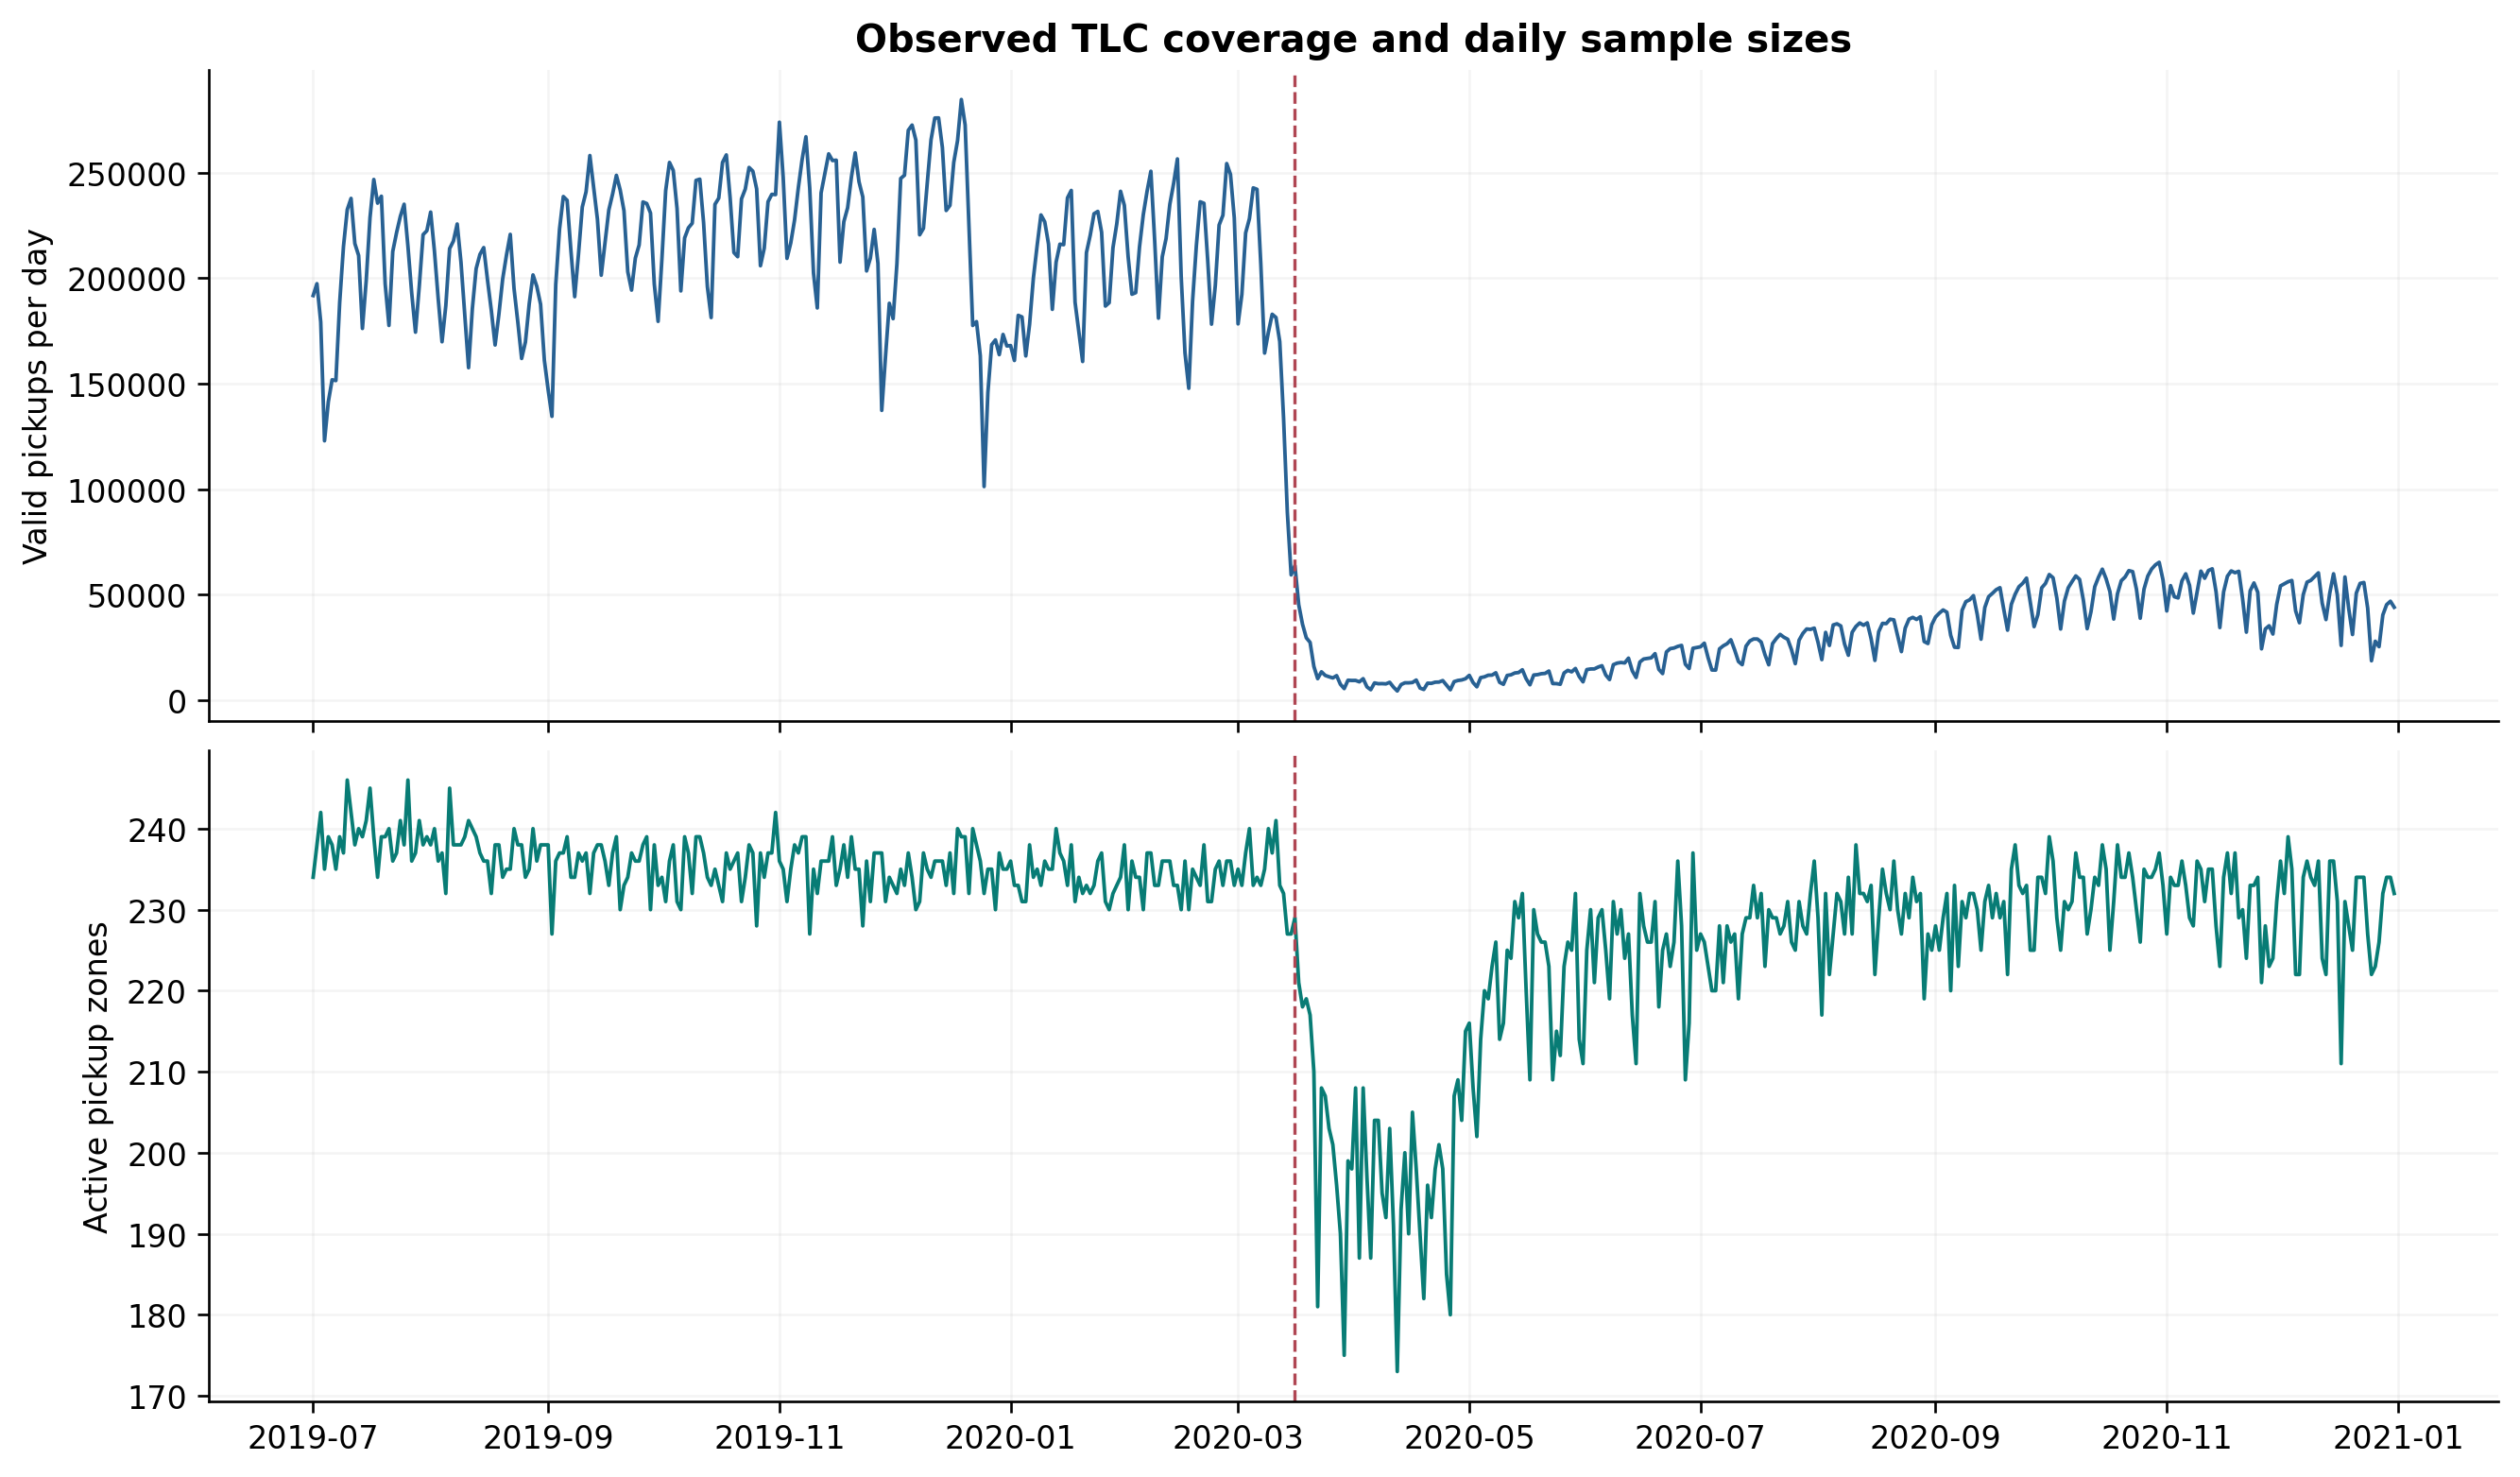

### fig03 order cusum

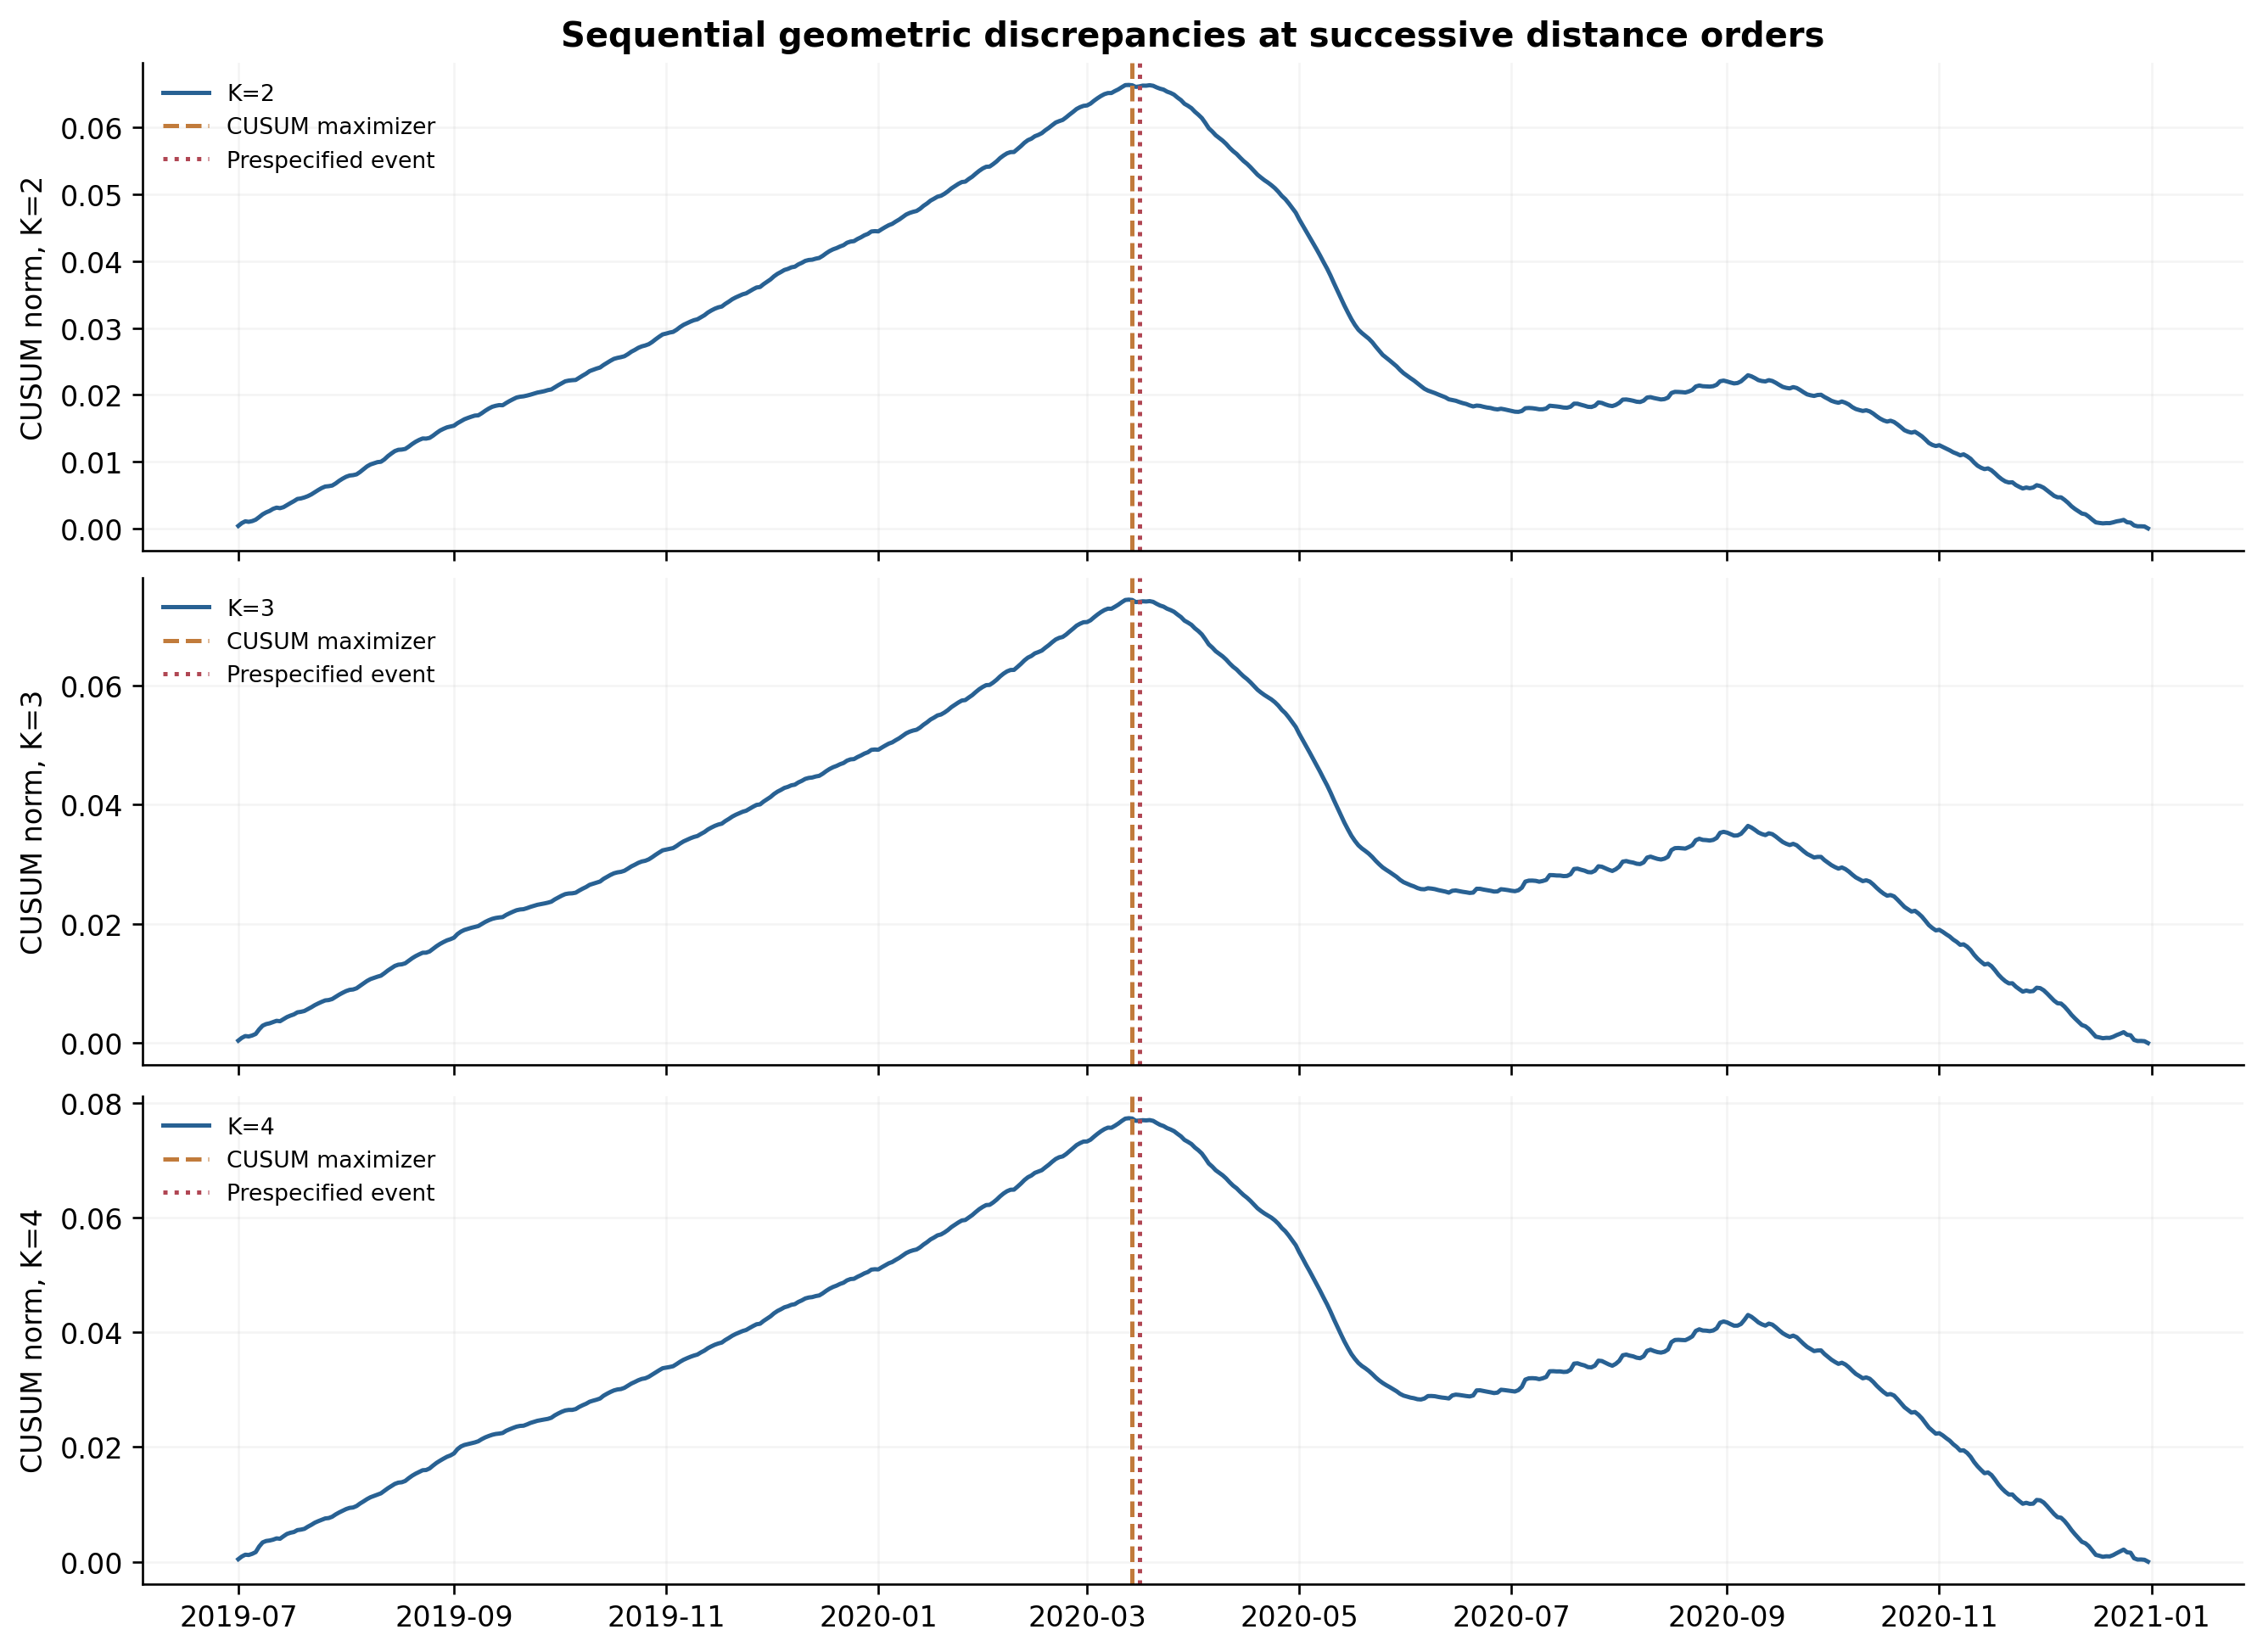

### fig04 pvalue sensitivity

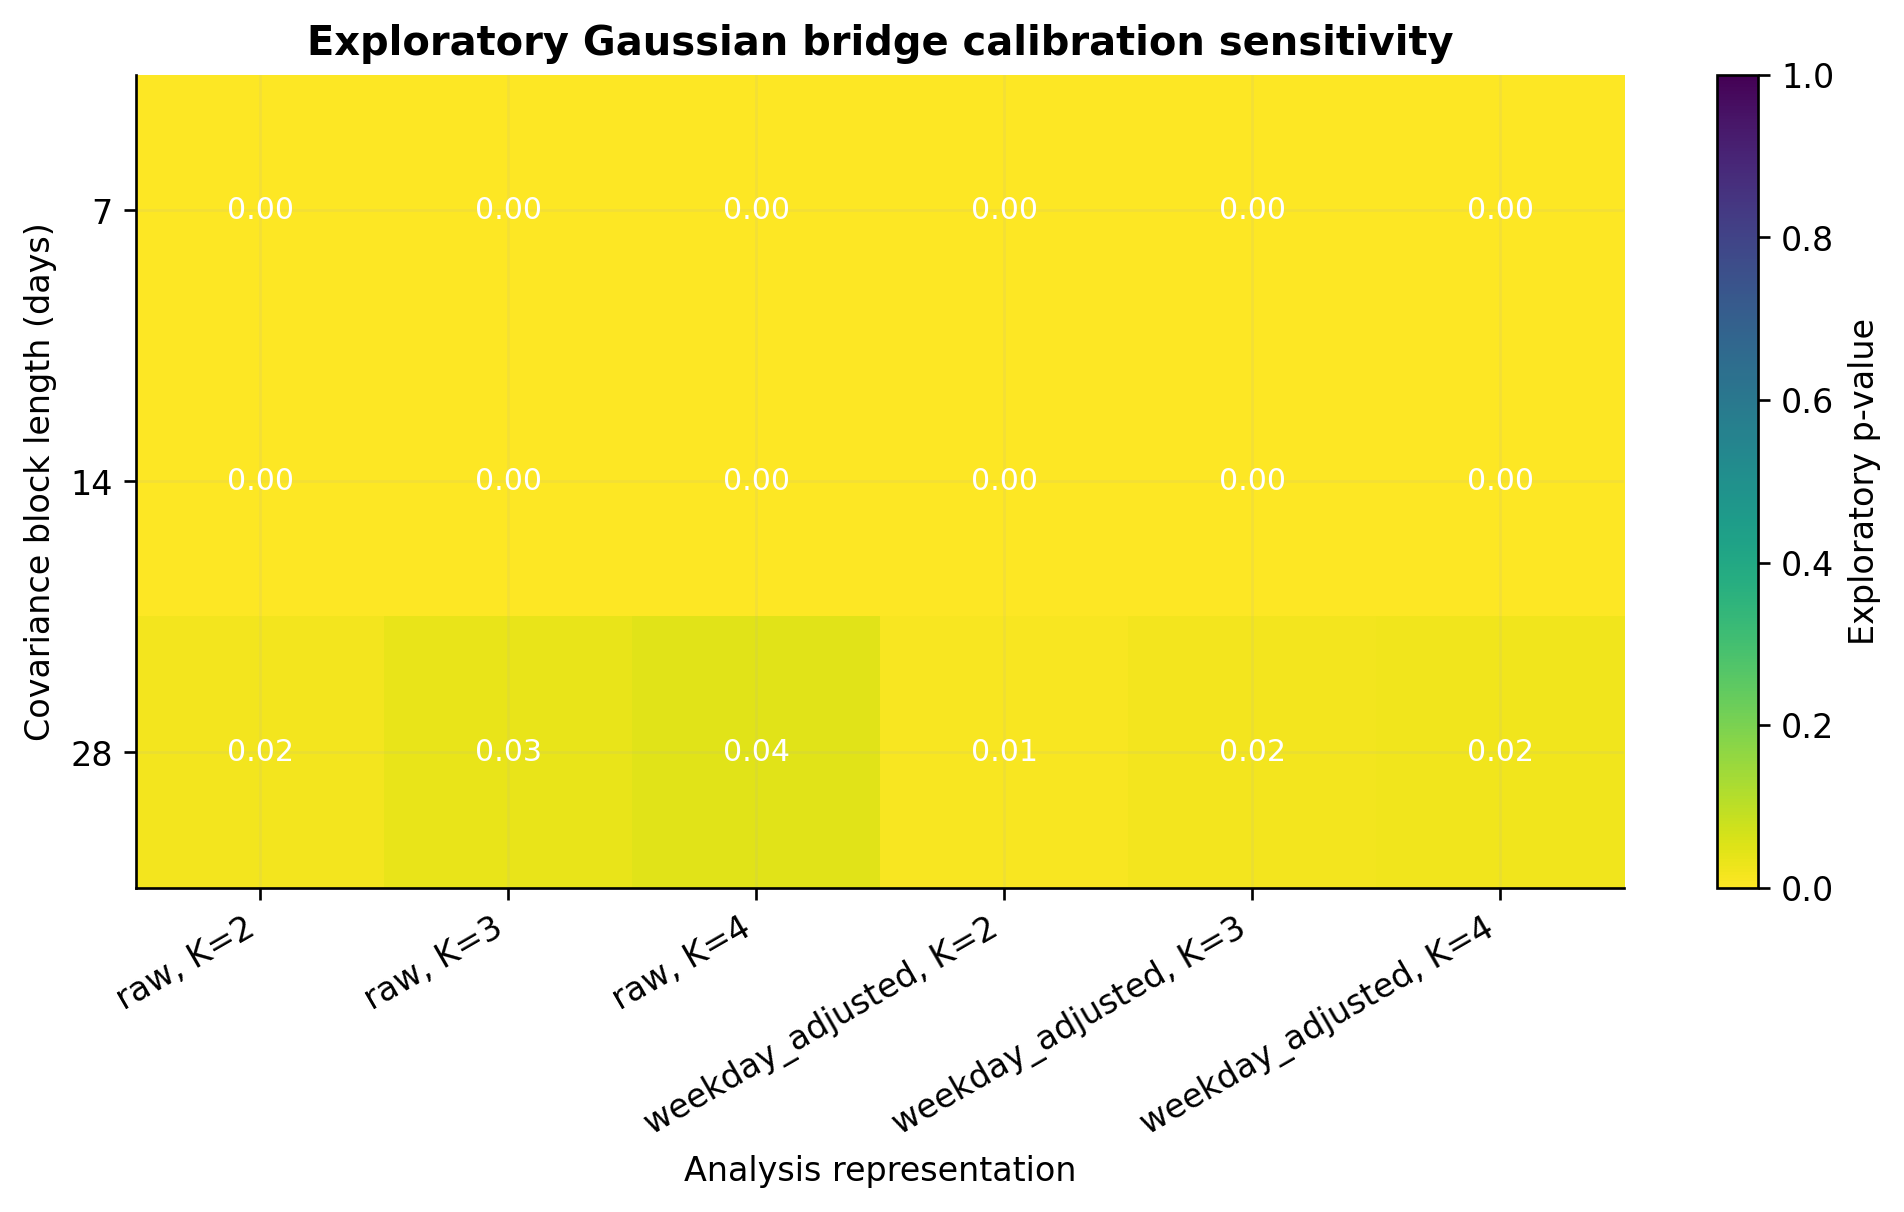

### fig05 zone composition

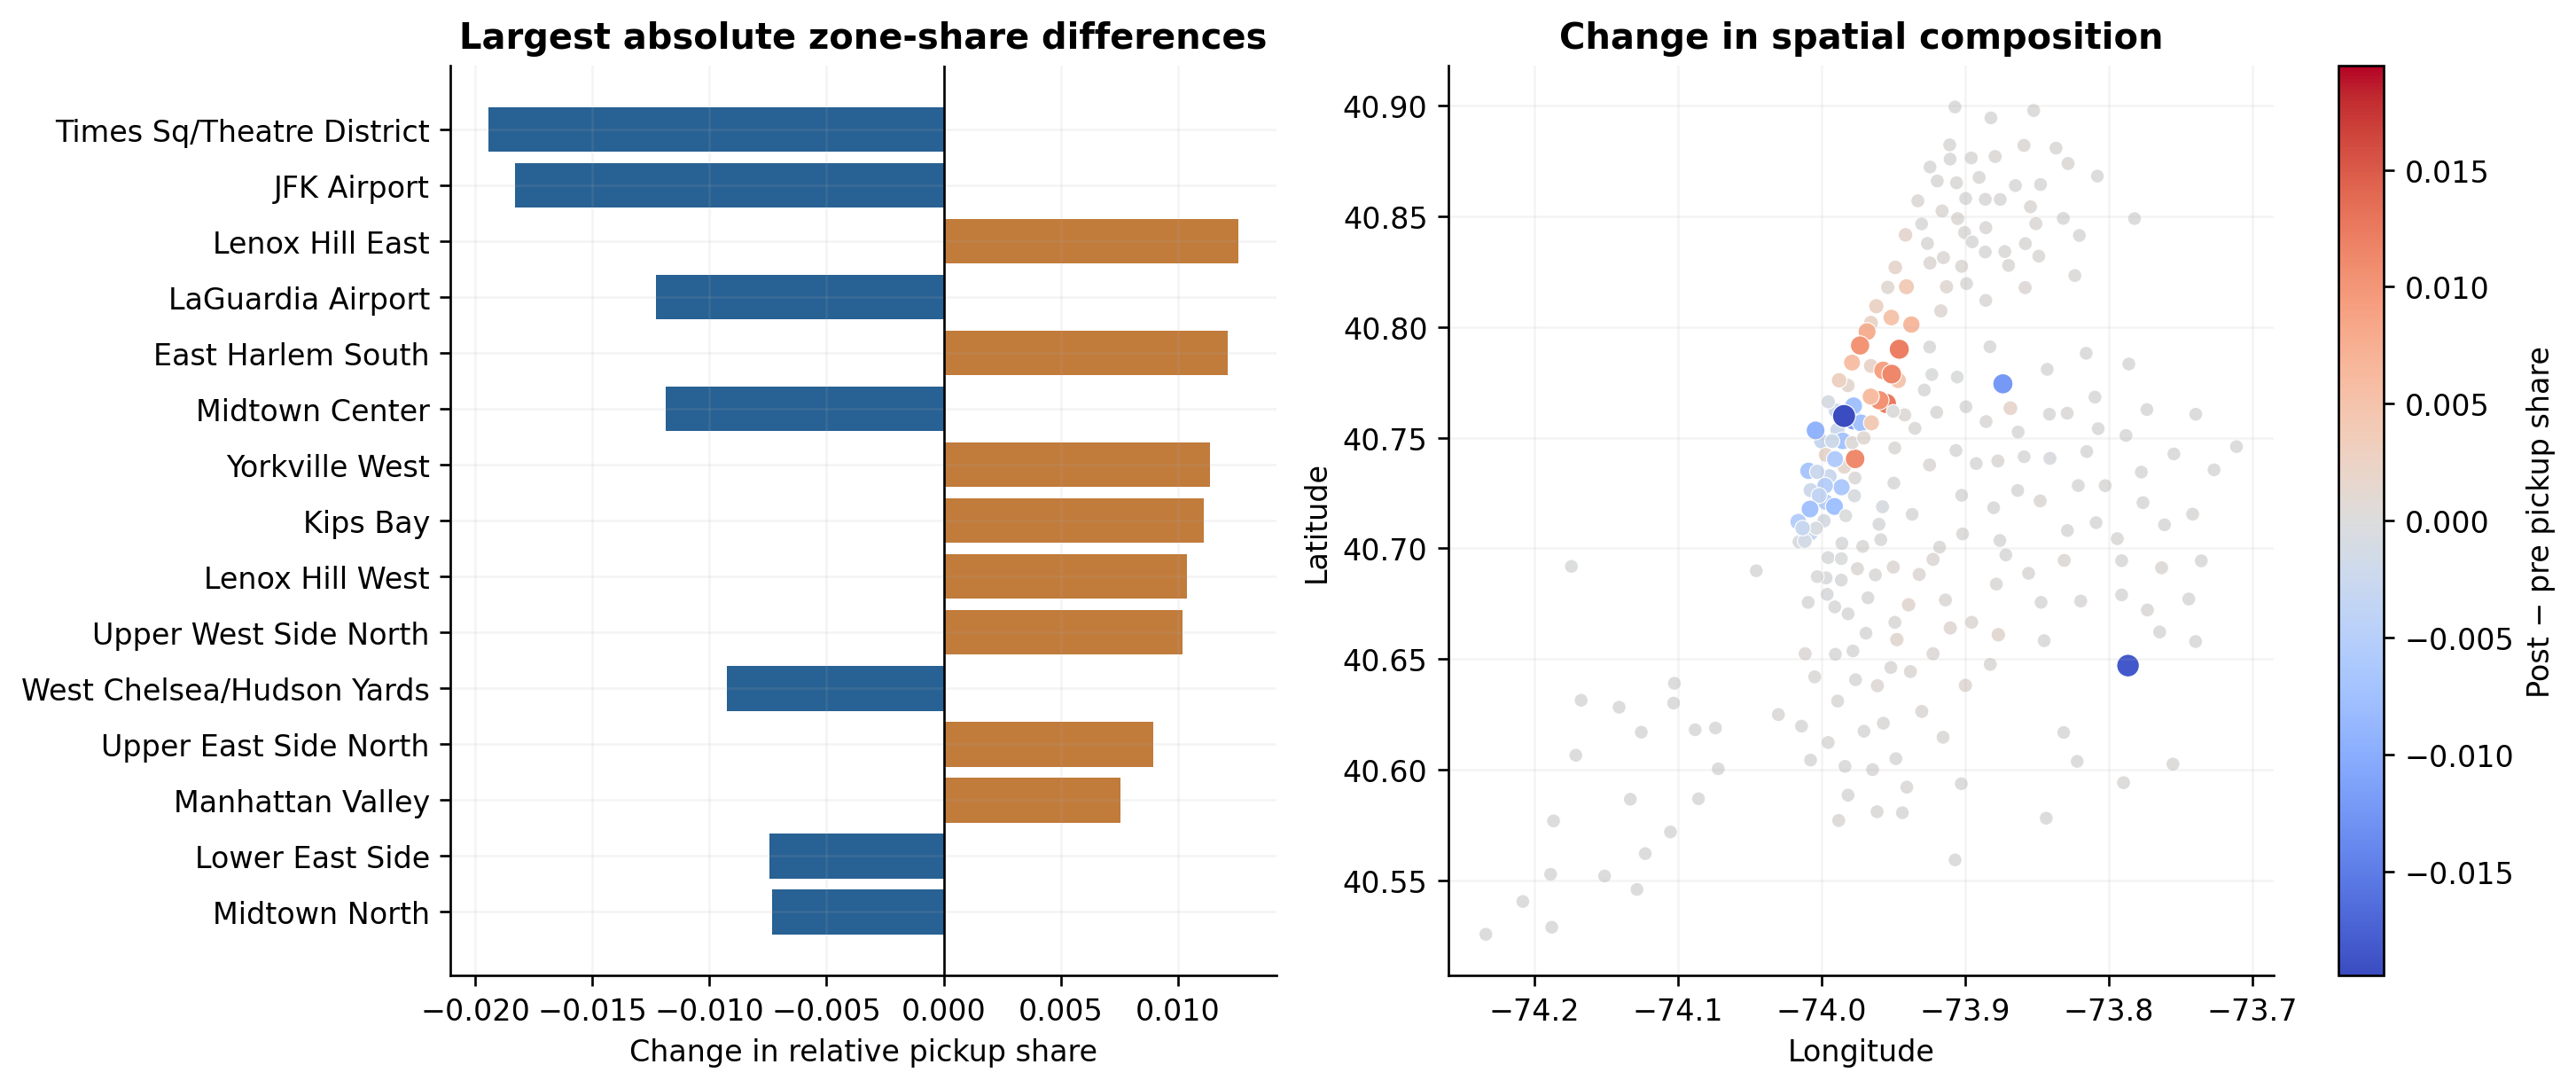

### fig06 dispersion mc error

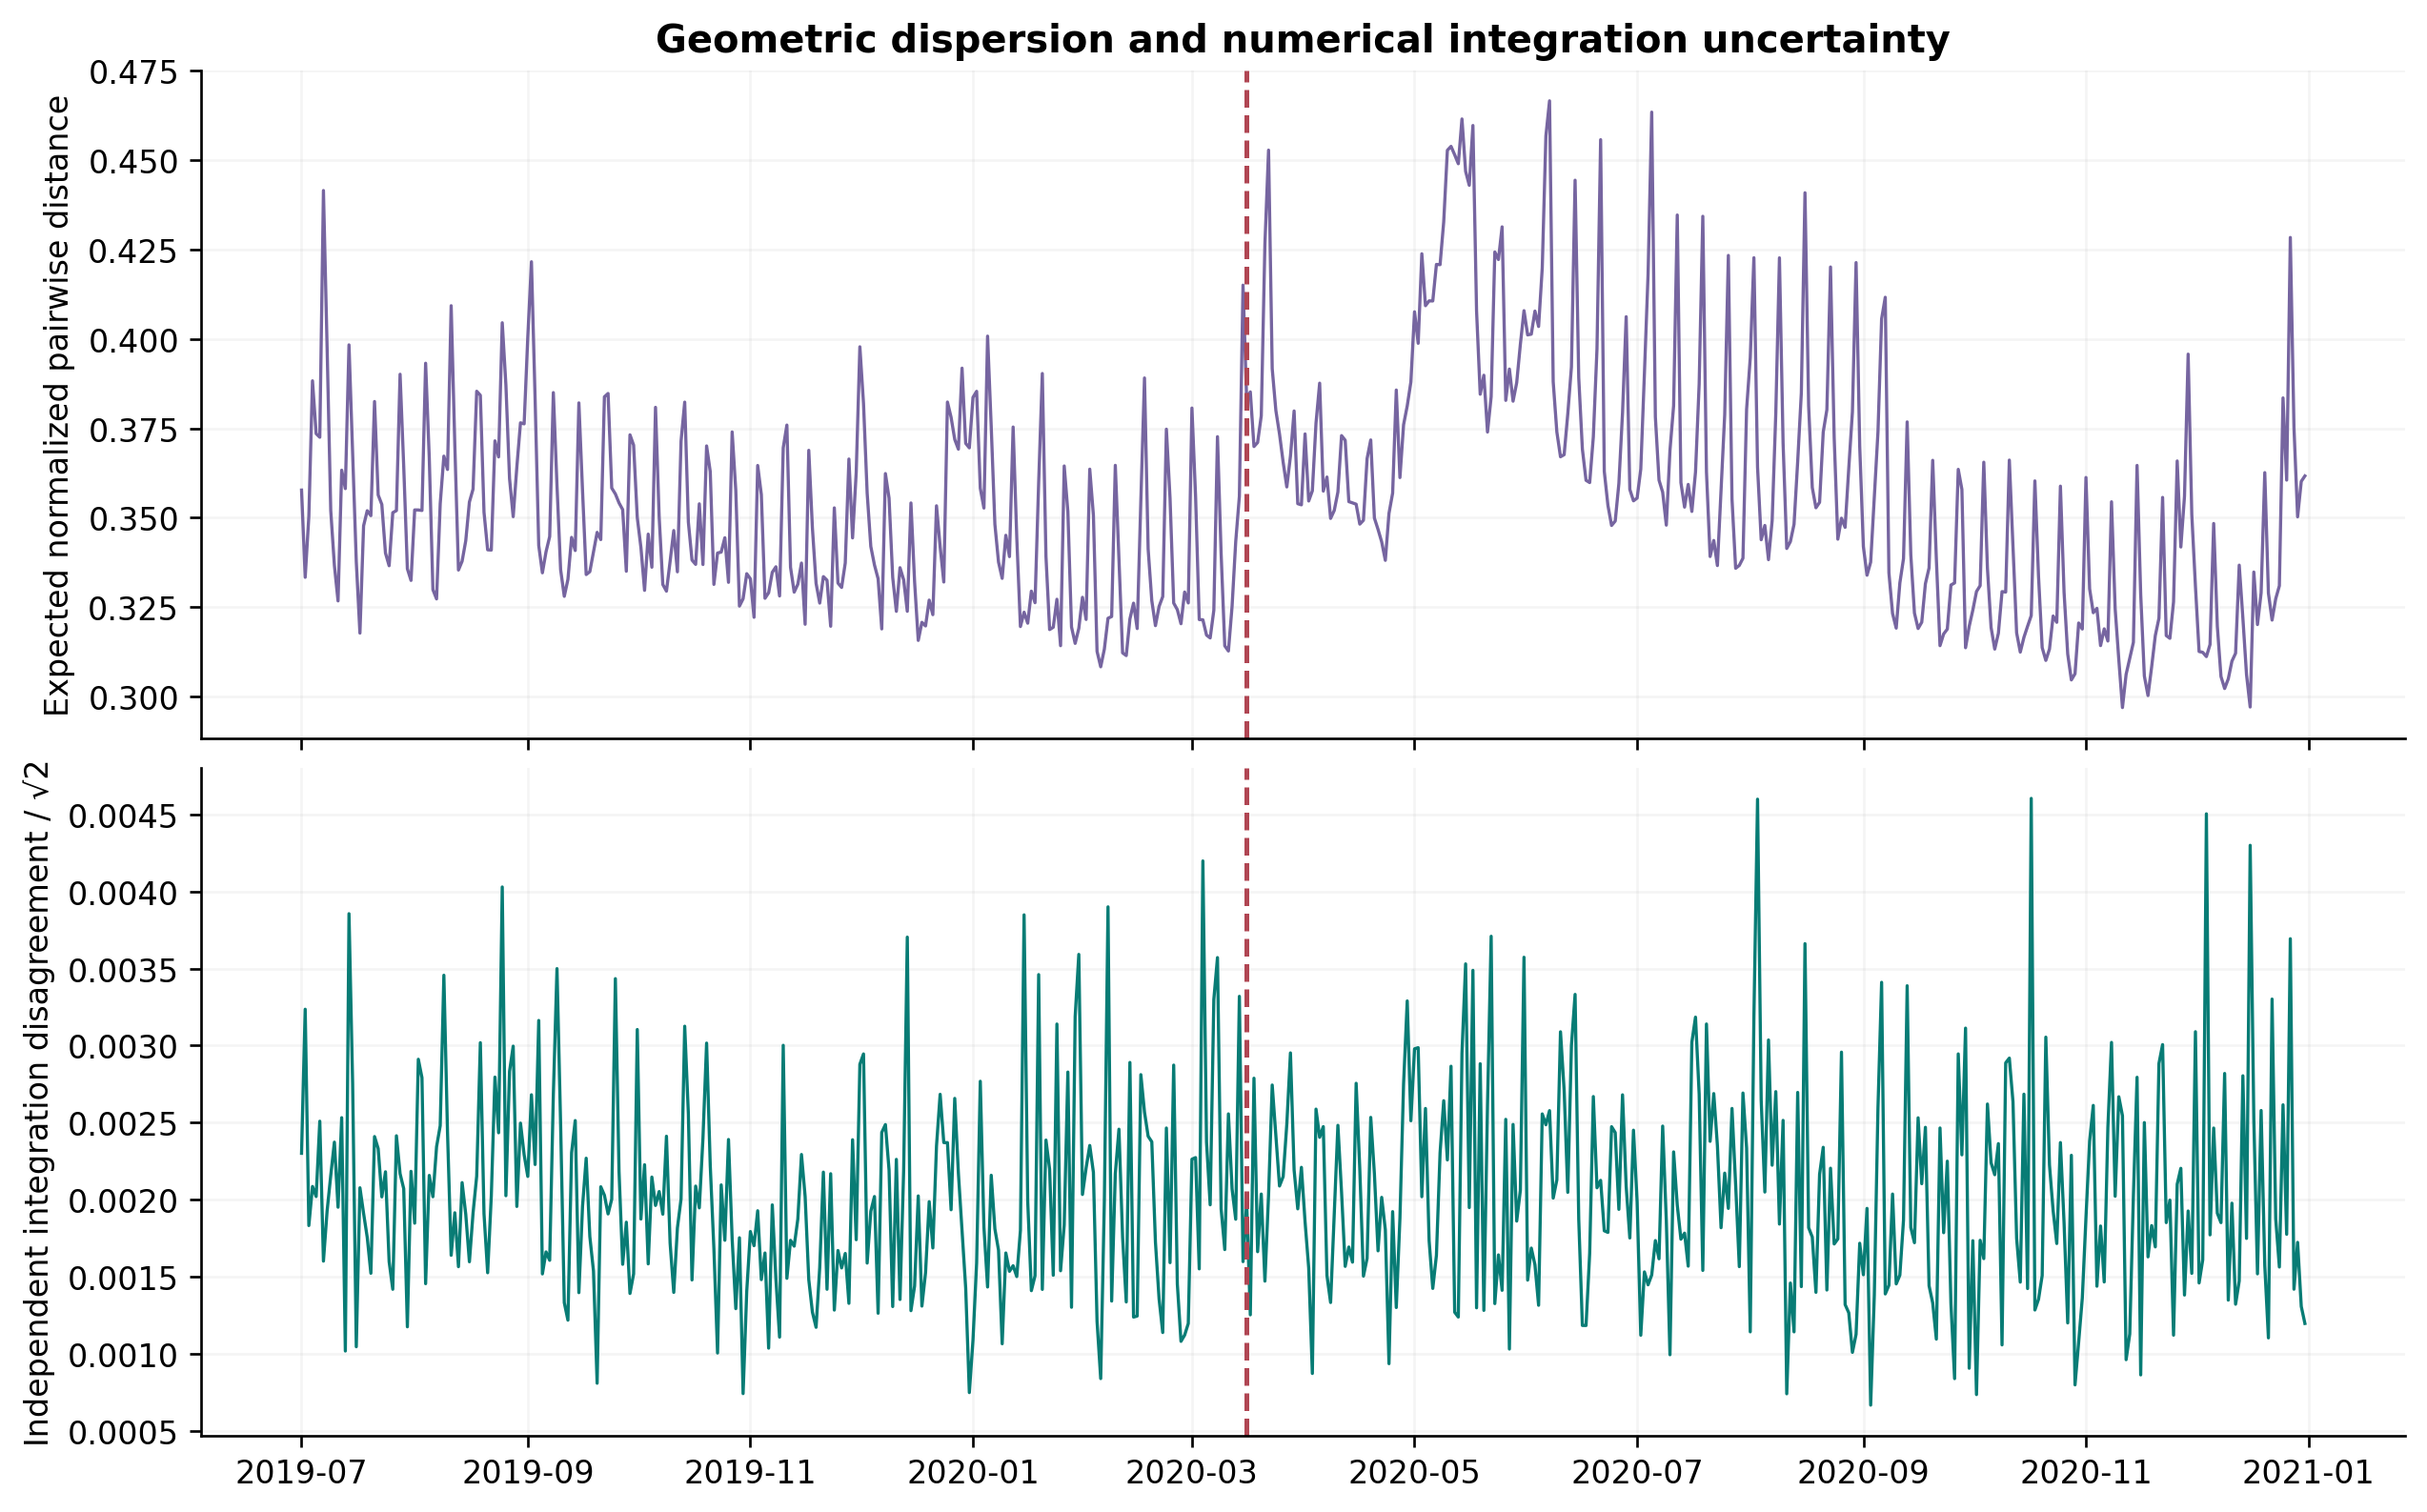

### fig07 dependence weekday

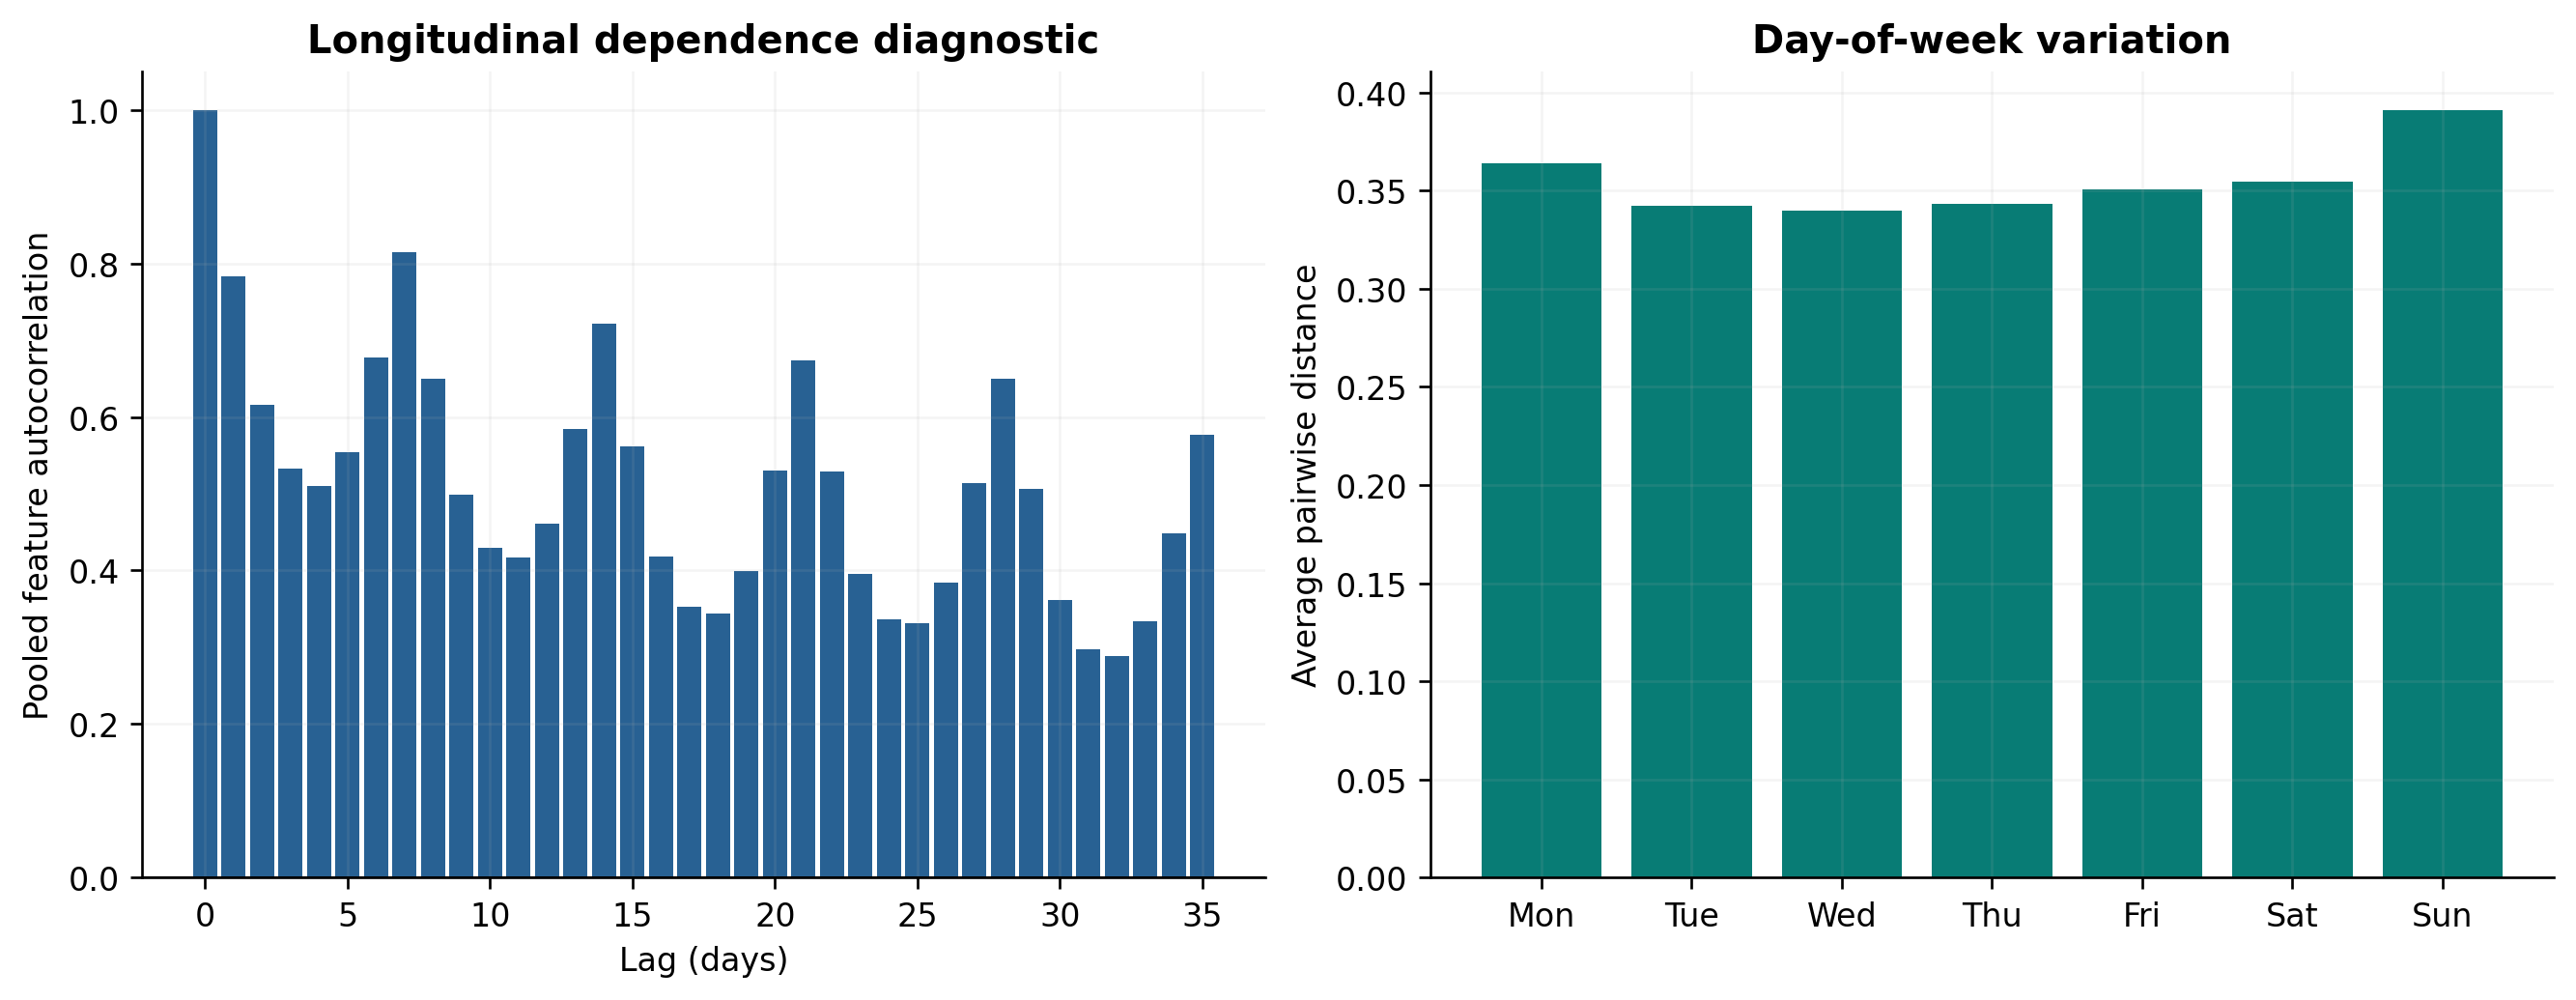

### fig08 prepost effects

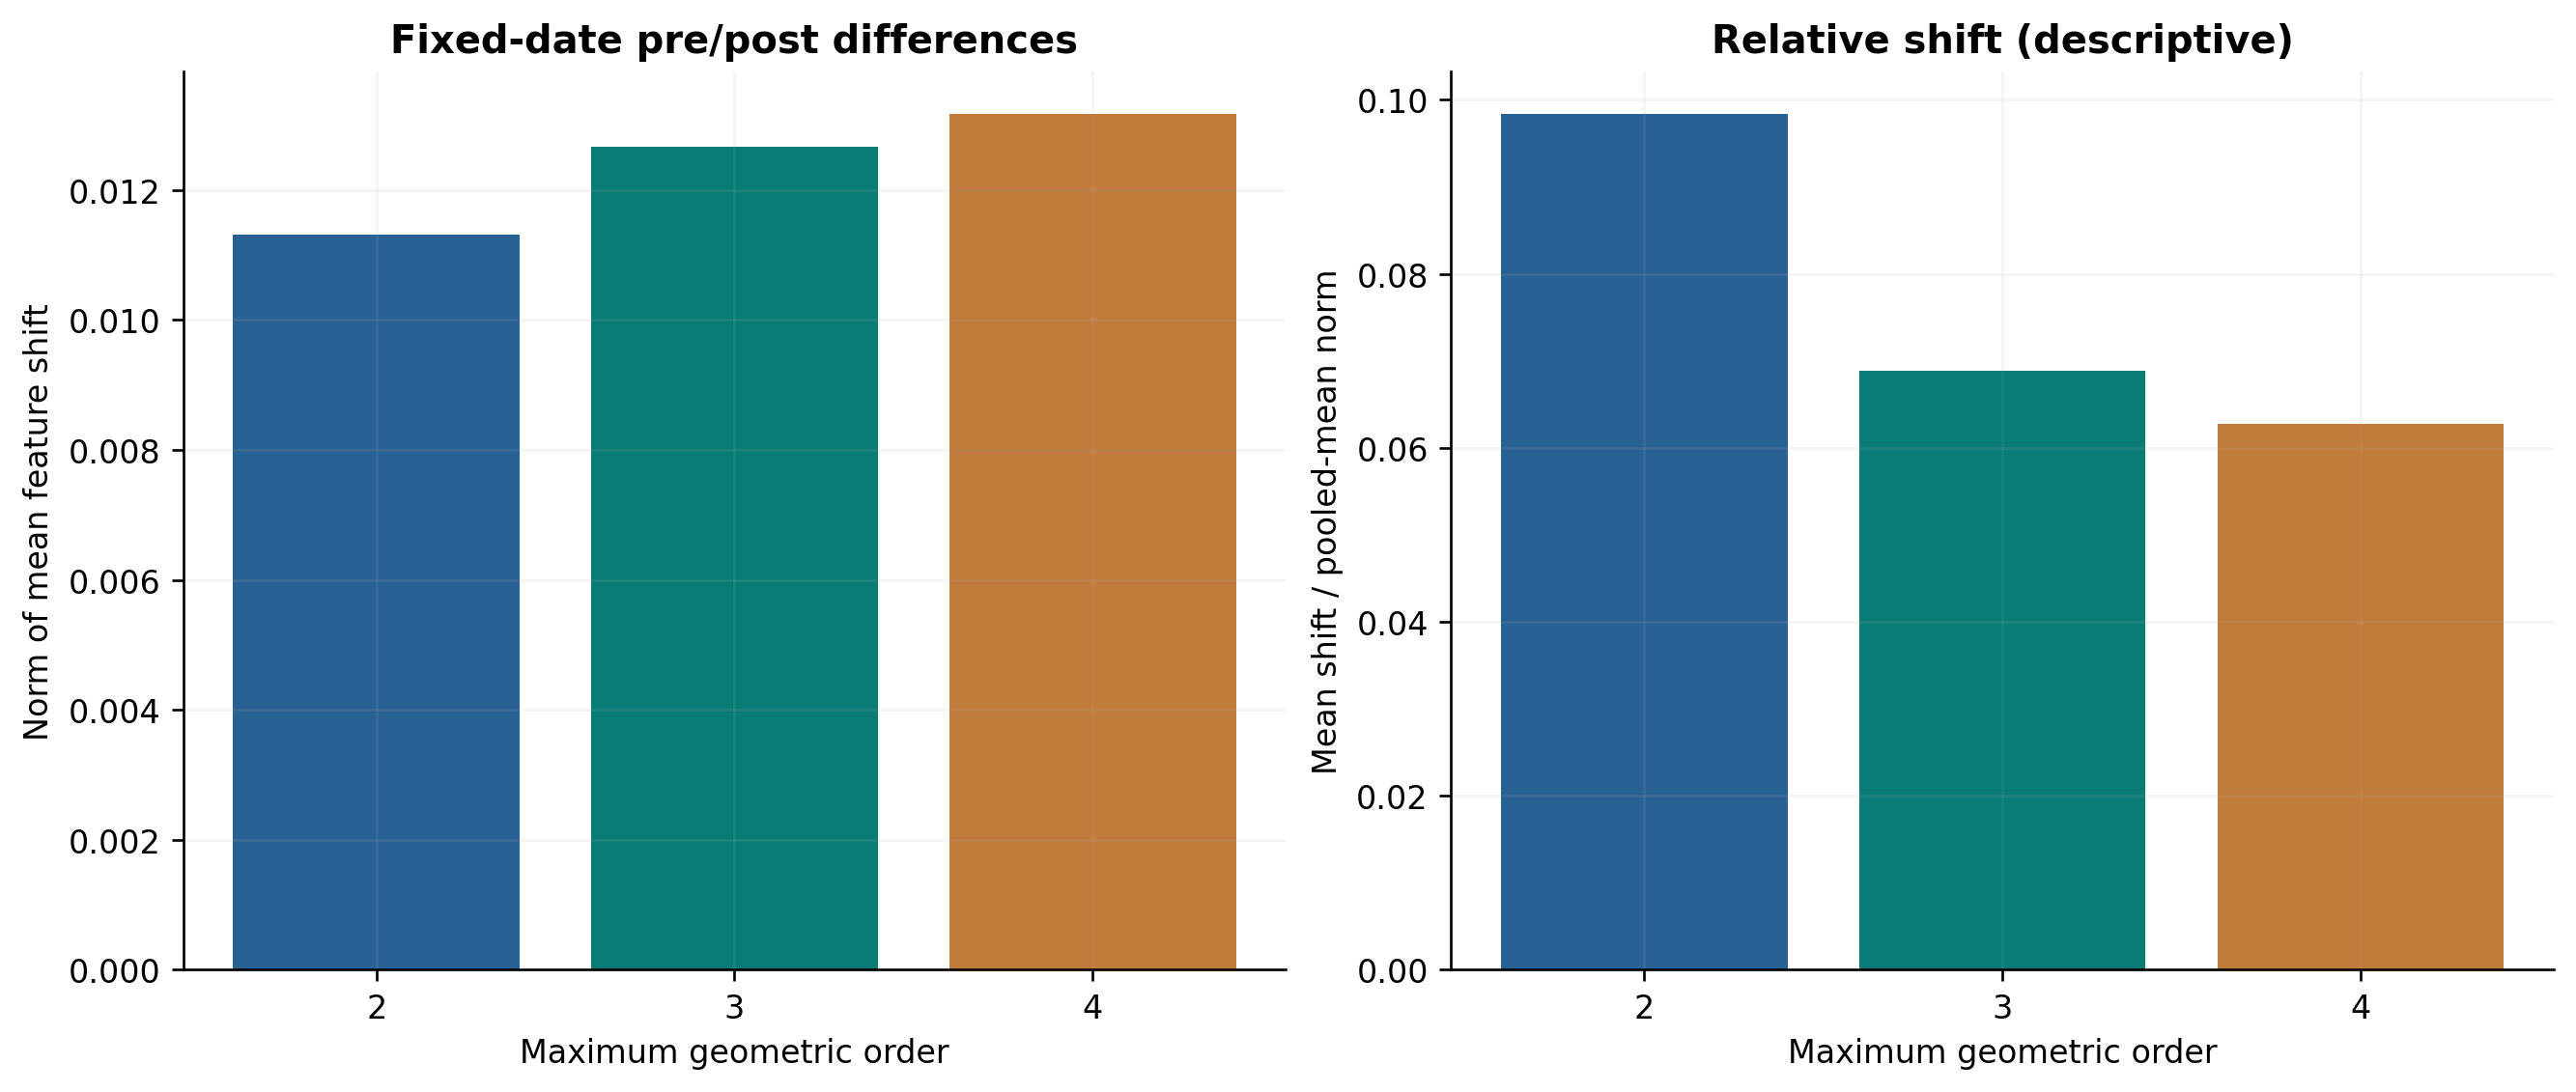

Results ZIP: /content/annealed_tlc_daily_outputs.zip


In [6]:
from IPython.display import display, Image, Markdown
if RUN_TLC_REAL_DATA:
    import pandas as pd
    out_dir=Path(REAL_DATA_OUTPUT)
    for label,path in [('CUSUM calibration sensitivity','cusum_calibration_sensitivity.csv'),
                       ('Fixed-date geometric effects','prespecified_date_effects.csv'),
                       ('Largest pickup-zone changes','zone_share_changes.csv')]:
        print('\n',label)
        df=pd.read_csv(out_dir/'tables'/path)
        display(df.head(20))
    for pic in ['fig01_daily_coverage','fig03_order_cusum','fig04_pvalue_sensitivity',
                'fig05_zone_composition','fig06_dispersion_mc_error',
                'fig07_dependence_weekday','fig08_prepost_effects']:
        img=out_dir/'figures'/(pic+'.png')
        if img.exists():
            display(Markdown('### '+pic.replace('_',' ')))
            display(Image(filename=str(img),width=900))
    print('Results ZIP:',out_dir.parent/(out_dir.name+'.zip'))

## 5. Reporting guardrails
A detected maximizer is **not** automatically statistically significant. The city-wide yellow-taxi composition may change due to sampling/reporting artifacts, day-of-week effects, and secular trends. Distinct-zone centroid distances do not track passenger origin at precise geocoordinates. The temporal null is not assumed true in this retrospective period. Findings should be reported descriptively pending independent assumptions checks.